# 06 — Extended analyses

The walkthrough for every analysis in [`docs/extended_analysis_report.md`](../docs/extended_analysis_report.md). The report holds the findings and advice; this notebook shows the tables and charts behind them.

**How this notebook works.** The code lives in `src/ext_*.py`. This notebook reads the saved `ext_` tables, so it opens in seconds. To recompute everything, set `REBUILD = True` (about 4 minutes), or run `python -m src.extended_analysis` from the repo root.

**Labels.** A = core, S = supporting, R = robustness, N = tested, not recommended. Nulls are kept on purpose, so nothing is selectively reported.

**Depends on** `01_cleaning` and `02_core_model` outputs. Part 5 lives in `04_robustness_extensions updated.ipynb`; order, event condition and the sign-up vs recall comparison are there, not here.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.extended_analysis import load_or_run

REBUILD = False  # True recomputes everything (about 4 minutes)
tables, summary = load_or_run(REBUILD)
pd.set_option("display.max_colwidth", 140, "display.max_columns", 30)


def show(name):
    return tables[name].round(3)


def chart(name):
    display(Image(filename=str(ROOT / "outputs" / "figures" / name), width=820))


print(f"{len(tables)} tables, {len(summary)} findings")

57 tables, 54 findings


## The menu

Every finding, with its interval and its p-value adjusted for testing many things at once. `p_adjusted` covers only the primary tests. The `answer` text is generated from the numbers, so it can't drift from them.

In [2]:
summary[["id", "tier", "answer", "estimate", "ci_low", "ci_high", "p", "p_adjusted"]].round(3)

,id,tier,answer,estimate,ci_low,ci_high,p,p_adjusted
0,A1a,Core,Attractiveness counts 20.2 (women) and 20.7 (men) points more in choices than in the survey,20.181,15.277,24.770,NaN,NaN
1,A1b,Core,"Stated attractiveness weight is stable after 3-4 weeks (r=0.75), so the gap is lasting bias, not noise",0.753,0.670,0.826,NaN,NaN
2,A1c,Core,One attractiveness point trades for 3.2 intelligence points for women and 6.3 for men,6.278,3.526,23.812,NaN,NaN
3,A1d,Core,"Gender differences are not clear: men minus women is +0.30 on attractiveness (p=0.13), -0.30 on sincerity (p=0.05) and -0.15 on intellig...",0.302,-0.086,0.679,0.127,0.182
4,A2a,Core,Asking what others want shrinks the attractiveness gap from 17.4 to 6.9 (women) and 15.1 to 8.7 (men),-3.640,-4.416,-2.755,0.001,0.003
5,A2b,Core,The same result for men,-3.091,-3.911,-2.263,0.001,0.003
6,A2c,Core,"On the same people, 'what drove my decisions' gives attractiveness 29.0 (women) and 36.3 (men), against 20.5 and 33.7 for 'what I look for'",-8.509,-12.610,-5.354,0.001,0.003
7,A2c2,Core,The same comparison for men,-2.613,-4.934,-0.422,0.011,0.023
8,A2d,Core,Only the direct question separates individuals: t=3.6 vs t=0.2 on attractiveness,0.027,NaN,NaN,0.000,0.003
9,A2e,Core,A 1-10 rating scale lowers men's stated attractiveness weight by 11.4 points against 100-point allocation,-11.428,-13.645,-9.390,0.001,NaN


## A1. Can I trust stated-importance surveys?

The published gap, whether stated answers are stable over time, what traits trade off for, and a formal gender test.

In [3]:
for name in ["a1_gaps", "a1_retest", "a1_tradeoffs", "a1_gender_test"]:
    print(name)
    display(show(name))

a1_gaps


,gender,label,stated,revealed,gap_pp,gap_ci_low,gap_ci_high
0,Women,Attractive,17.676,37.858,20.181,15.277,24.770
1,Women,Sincere,18.273,9.176,-9.097,-14.449,-3.999
2,Women,Intelligent,21.189,9.372,-11.817,-16.538,-7.076
3,Women,Fun,17.507,19.804,2.297,-2.965,7.621
4,Women,Ambitious,12.738,1.381,-11.357,-13.273,-7.208
5,Women,Shared interests,12.617,22.409,9.792,5.296,13.974
6,Men,Attractive,26.692,47.367,20.675,15.637,25.343
7,Men,Sincere,16.574,2.186,-14.388,-16.996,-9.774
8,Men,Intelligent,19.511,6.028,-13.483,-17.759,-9.803
9,Men,Fun,17.208,24.034,6.826,2.557,10.967


a1_retest


,interval,attribute,people,correlation,ci_low,ci_high,mean_shift_pp
0,Day after,Attractive,386,0.751,0.692,0.805,4.249
1,Day after,Sincere,386,0.642,0.567,0.709,-1.705
2,Day after,Intelligent,386,0.578,0.481,0.666,-2.796
3,Day after,Fun,386,0.519,0.430,0.595,0.091
4,Day after,Ambitious,386,0.574,0.500,0.647,-0.897
5,Day after,Shared interests,386,0.563,0.479,0.639,1.058
6,3-4 weeks later,Attractive,200,0.753,0.670,0.826,3.534
7,3-4 weeks later,Sincere,200,0.703,0.554,0.817,-0.965
8,3-4 weeks later,Intelligent,200,0.638,0.525,0.736,-1.772
9,3-4 weeks later,Fun,200,0.462,0.333,0.588,-1.320


a1_tradeoffs


,gender,one_point_of,equals_points_of,ratio,ci_low,ci_high,share_of_draws_with_positive_denominator
0,Women,Attractive,Intelligent,3.198,1.998,7.008,1.000
1,Women,Attractive,Fun,1.966,1.446,2.725,1.000
2,Women,Attractive,Shared interests,1.840,1.446,2.386,1.000
3,Men,Attractive,Intelligent,6.278,3.526,23.812,0.993
4,Men,Attractive,Fun,1.948,1.583,2.435,1.000
5,Men,Attractive,Shared interests,2.585,2.022,3.465,1.000


a1_gender_test


,attribute,men_coef,women_coef,men_minus_women,ci_low,ci_high,p
0,Attractive,1.904,1.602,0.302,-0.086,0.679,0.127
1,Sincere,0.088,0.388,-0.300,-0.579,-0.002,0.051
2,Intelligent,0.242,0.397,-0.154,-0.478,0.116,0.257
3,Fun,0.966,0.838,0.128,-0.141,0.393,0.341
4,Ambitious,-0.063,0.058,-0.121,-0.373,0.140,0.373
5,Shared interests,0.819,0.948,-0.129,-0.426,0.122,0.363


## A2. Can I write a better survey?

Same people, different questions. `error_change_vs_baseline` below zero means closer to real choices. The ladder compares questions on the same people, against 'what I look for' the day after. `a2_individual_signal` asks whether an answer predicts that person's own behaviour.

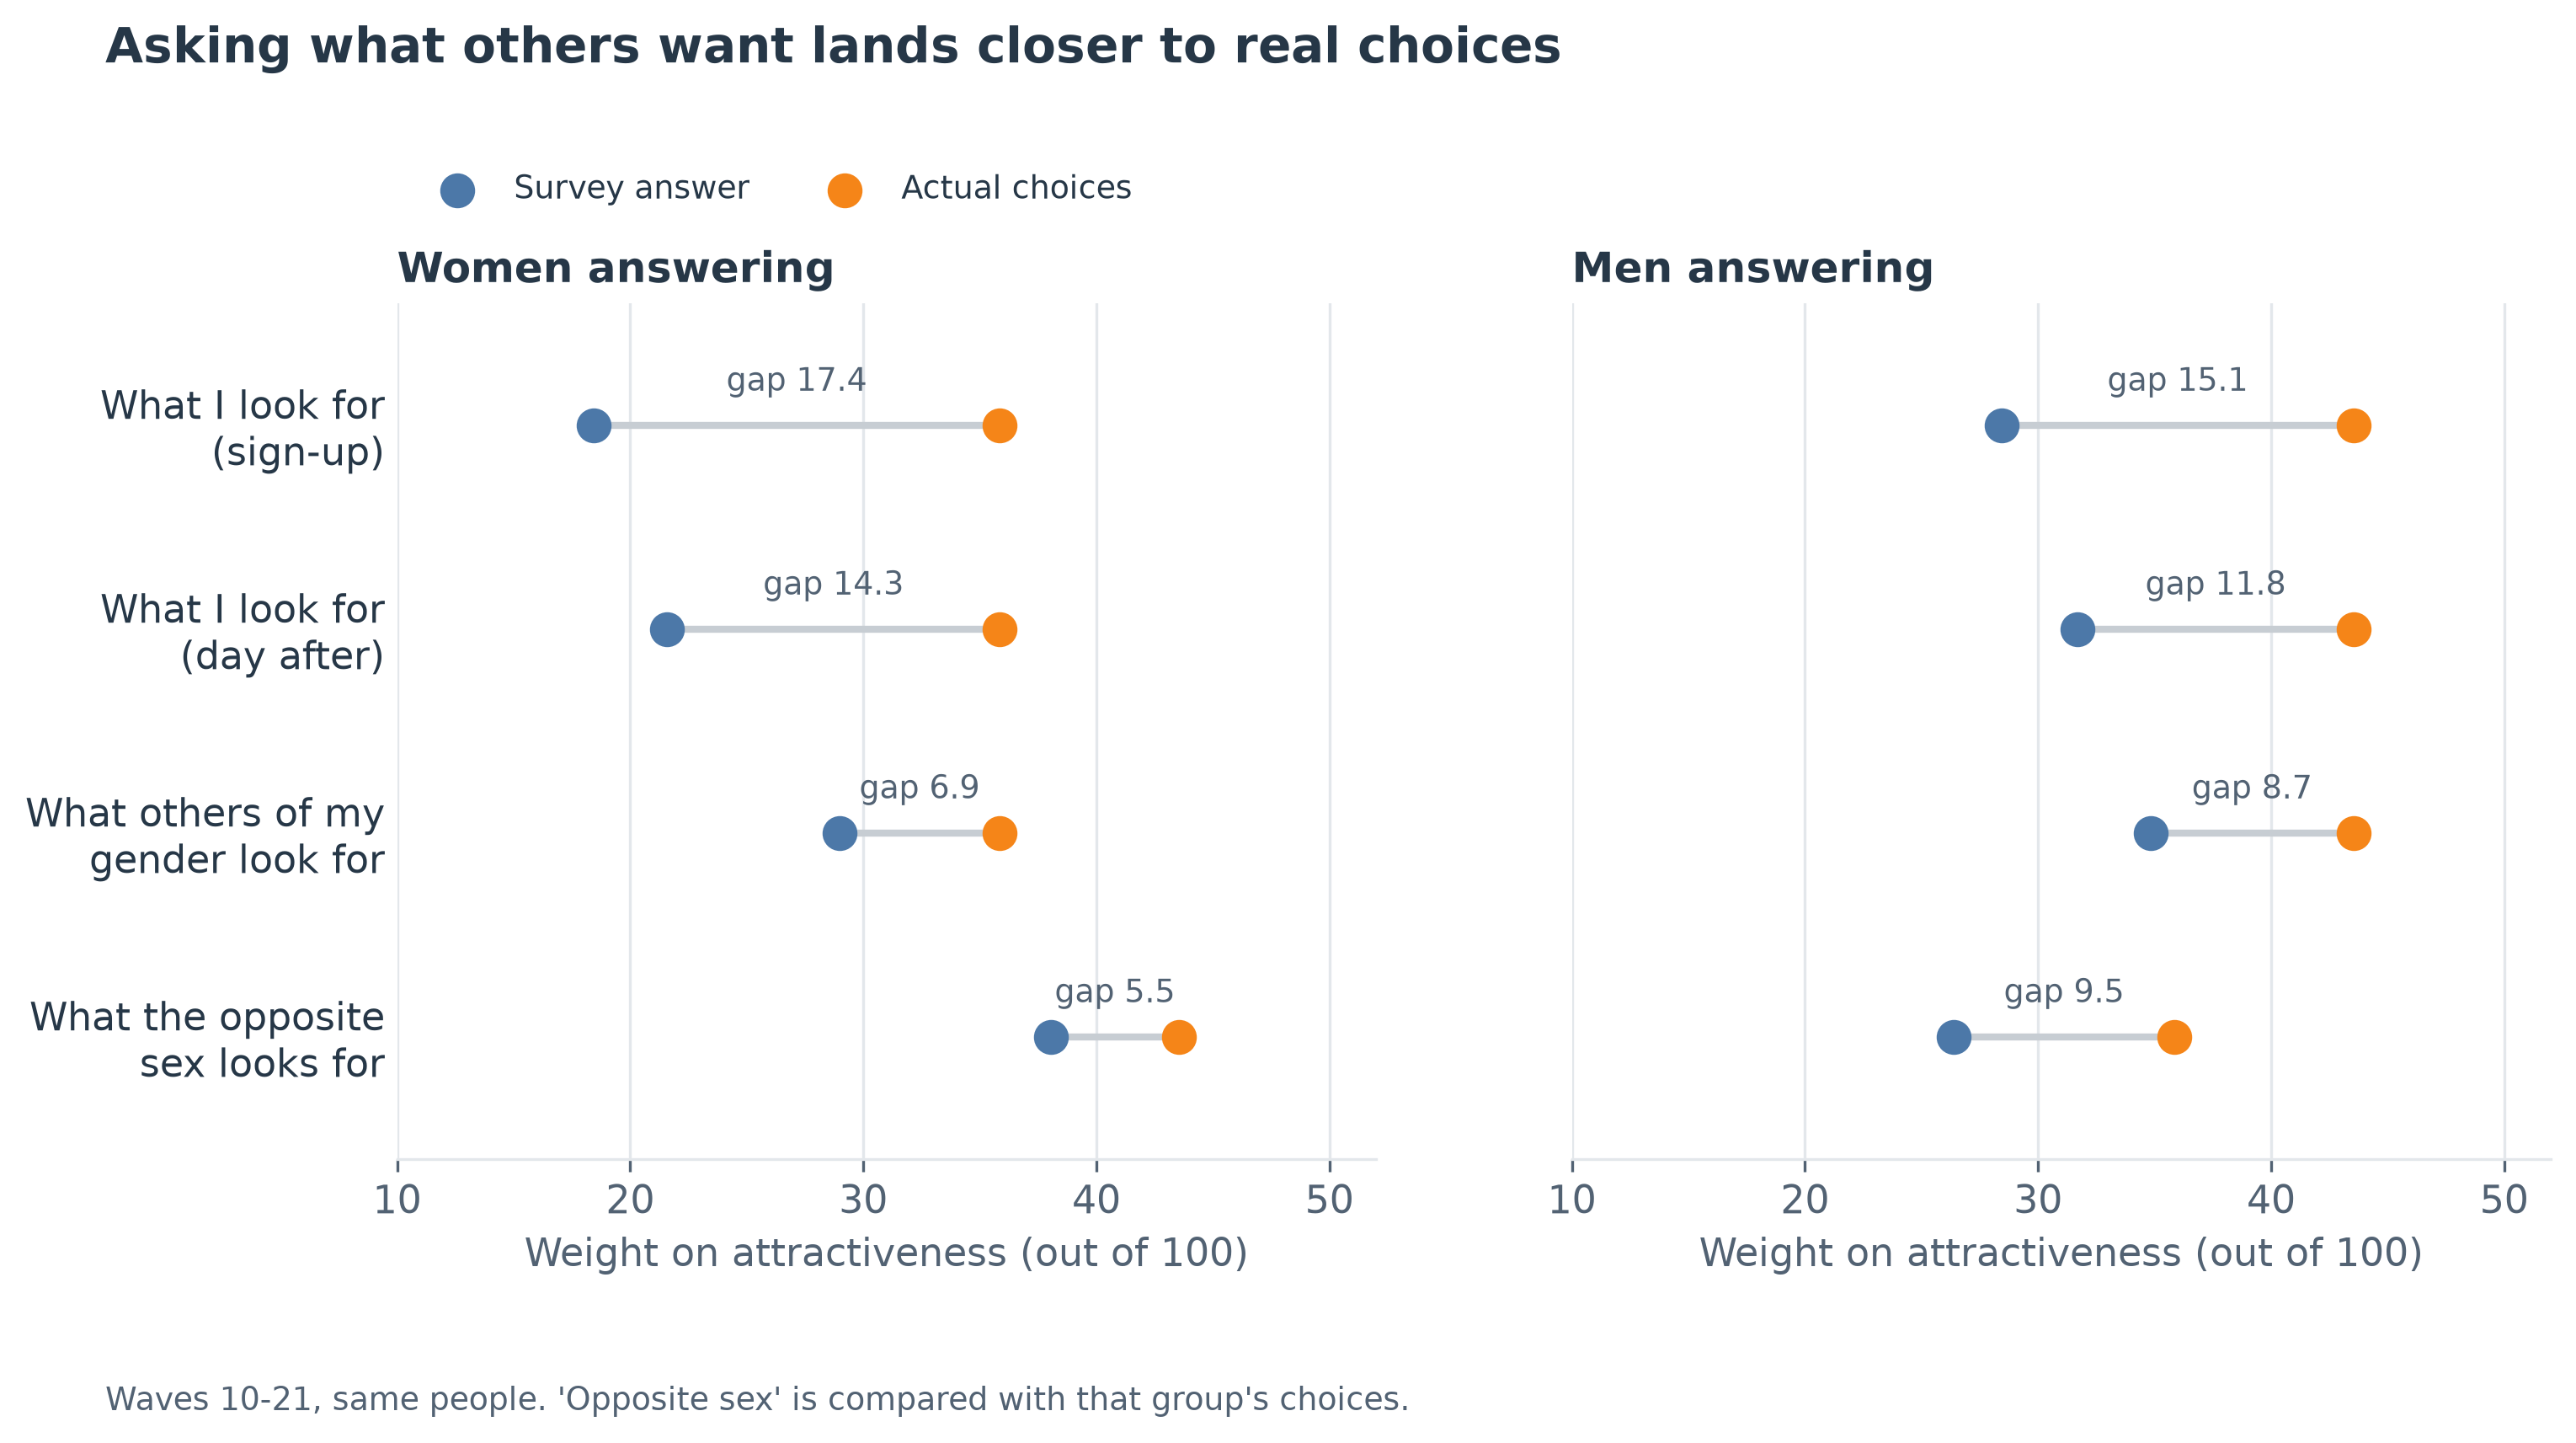

In [4]:
chart("ext_a2_survey_wording.png")

In [5]:
for name in ["a2_wording", "a2_ladder", "a2_individual_signal", "a2_survey_format"]:
    print(name)
    display(show(name))

a2_wording


,gender,question,suffix,people,attractive_share,attractive_target,attractive_gap,gap_ci_low,gap_ci_high,mean_abs_error,error_ci_low,error_ci_high,error_change_vs_baseline,error_change_ci_low,error_change_ci_high,error_change_p,gap_change_vs_baseline,gap_change_ci_low,gap_change_ci_high,gap_change_p
0,Women,What I look for (sign-up),1_1,131,18.438,35.845,17.407,12.010,22.766,11.059,8.953,13.154,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Women,What others of my gender look for,4_1,131,28.981,35.845,6.864,1.481,12.022,7.420,5.357,9.773,-3.640,-4.416,-2.755,0.001,-10.543,-13.060,-8.185,0.001
2,Women,What the opposite sex looks for,2_1,131,38.061,43.527,5.466,-1.856,11.565,7.145,4.623,9.082,-3.914,-7.177,-1.202,0.007,-11.941,-21.266,-3.618,0.005
3,Women,What I look for (day after),1_2,117,21.592,35.845,14.253,8.674,19.721,9.768,7.629,11.957,-1.361,-1.840,-0.895,0.001,-3.187,-4.676,-1.738,0.001
4,Women,What I look for (3-4 weeks later),1_3,64,22.965,35.845,12.880,6.384,19.464,10.074,7.821,12.277,-0.996,-2.066,-0.190,0.013,-3.926,-6.508,-1.442,0.005
5,Men,What I look for (sign-up),1_1,137,28.452,43.527,15.074,8.619,20.958,11.639,9.008,13.515,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Men,What others of my gender look for,4_1,137,34.833,43.527,8.694,1.772,14.878,8.548,5.743,10.557,-3.091,-3.911,-2.263,0.001,-6.381,-8.530,-4.100,0.001
7,Men,What the opposite sex looks for,2_1,137,26.384,35.845,9.461,3.745,15.104,8.848,6.729,11.173,-2.791,-5.554,0.782,0.167,-5.614,-13.855,3.088,0.213
8,Men,What I look for (day after),1_2,121,31.709,43.527,11.817,5.533,17.404,10.188,7.526,12.142,-1.229,-1.795,-0.729,0.001,-2.996,-4.580,-1.529,0.001
9,Men,What I look for (3-4 weeks later),1_3,52,32.163,43.527,11.364,4.589,17.611,10.650,7.797,12.698,-0.632,-1.427,0.086,0.087,-3.490,-6.433,-0.808,0.019


a2_ladder


,gender,question,suffix,people,attractive_share,attractive_target,attractive_gap,gap_ci_low,gap_ci_high,mean_abs_error,error_ci_low,error_ci_high,error_change_vs_baseline,error_change_ci_low,error_change_ci_high,error_change_p,gap_change_vs_baseline,gap_change_ci_low,gap_change_ci_high,gap_change_p
0,Women,What I look for (sign-up),1_1,55,18.043,35.589,17.546,8.594,24.569,11.938,8.929,14.421,1.029,0.187,1.870,0.021,2.487,0.122,4.756,0.043
1,Women,What I look for (day after),1_2,55,20.530,35.589,15.058,5.933,21.704,10.909,7.842,13.356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Women,What drove my decisions (day after),7_2,55,29.040,35.589,6.549,-3.498,13.678,8.414,5.787,11.313,-2.495,-3.311,-0.742,0.003,-8.509,-12.610,-5.354,0.001
3,Men,What I look for (sign-up),1_1,54,29.449,44.897,15.449,5.910,24.876,12.117,8.448,14.222,1.374,0.497,2.199,0.005,4.284,1.577,7.256,0.003
4,Men,What I look for (day after),1_2,54,33.733,44.897,11.165,1.603,20.381,10.742,6.893,13.111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Men,What drove my decisions (day after),7_2,54,36.345,44.897,8.552,-0.790,18.067,9.323,5.744,11.582,-1.419,-2.219,-0.430,0.007,-2.613,-4.934,-0.422,0.011


a2_individual_signal


,question,attribute,average_slope,tilt_per_sd,t_stat,p,people
0,What I look for (sign-up),Attractive,0.175,0.027,3.577,0.000,268
1,What I look for (sign-up),Sincere,0.006,0.025,2.699,0.007,268
2,What I look for (sign-up),Intelligent,0.025,0.027,3.070,0.002,268
3,What I look for (sign-up),Fun,0.096,0.006,0.769,0.442,268
4,What I look for (sign-up),Ambitious,-0.002,0.007,0.893,0.372,268
5,What I look for (sign-up),Shared interests,0.110,0.029,3.835,0.000,268
6,What others of my gender look for,Attractive,0.180,0.002,0.236,0.813,268
7,What others of my gender look for,Sincere,0.005,-0.007,-0.734,0.463,268
8,What others of my gender look for,Intelligent,0.026,0.001,0.101,0.920,268
9,What others of my gender look for,Fun,0.095,0.015,1.849,0.064,268


a2_survey_format


,gender,rating_scale,hundred_points,people_rating,people_points,difference_estimate,ci_low,ci_high,p
0,Women,14.911,18.281,40,183,-3.370,-5.053,-1.686,0.001
1,Men,17.459,28.887,44,185,-11.428,-13.645,-9.390,0.001


## A3. Should I collect more survey data or more behaviour?

Predicting later yeses on events the model has not seen. The last table is the pre-event pair ranking.

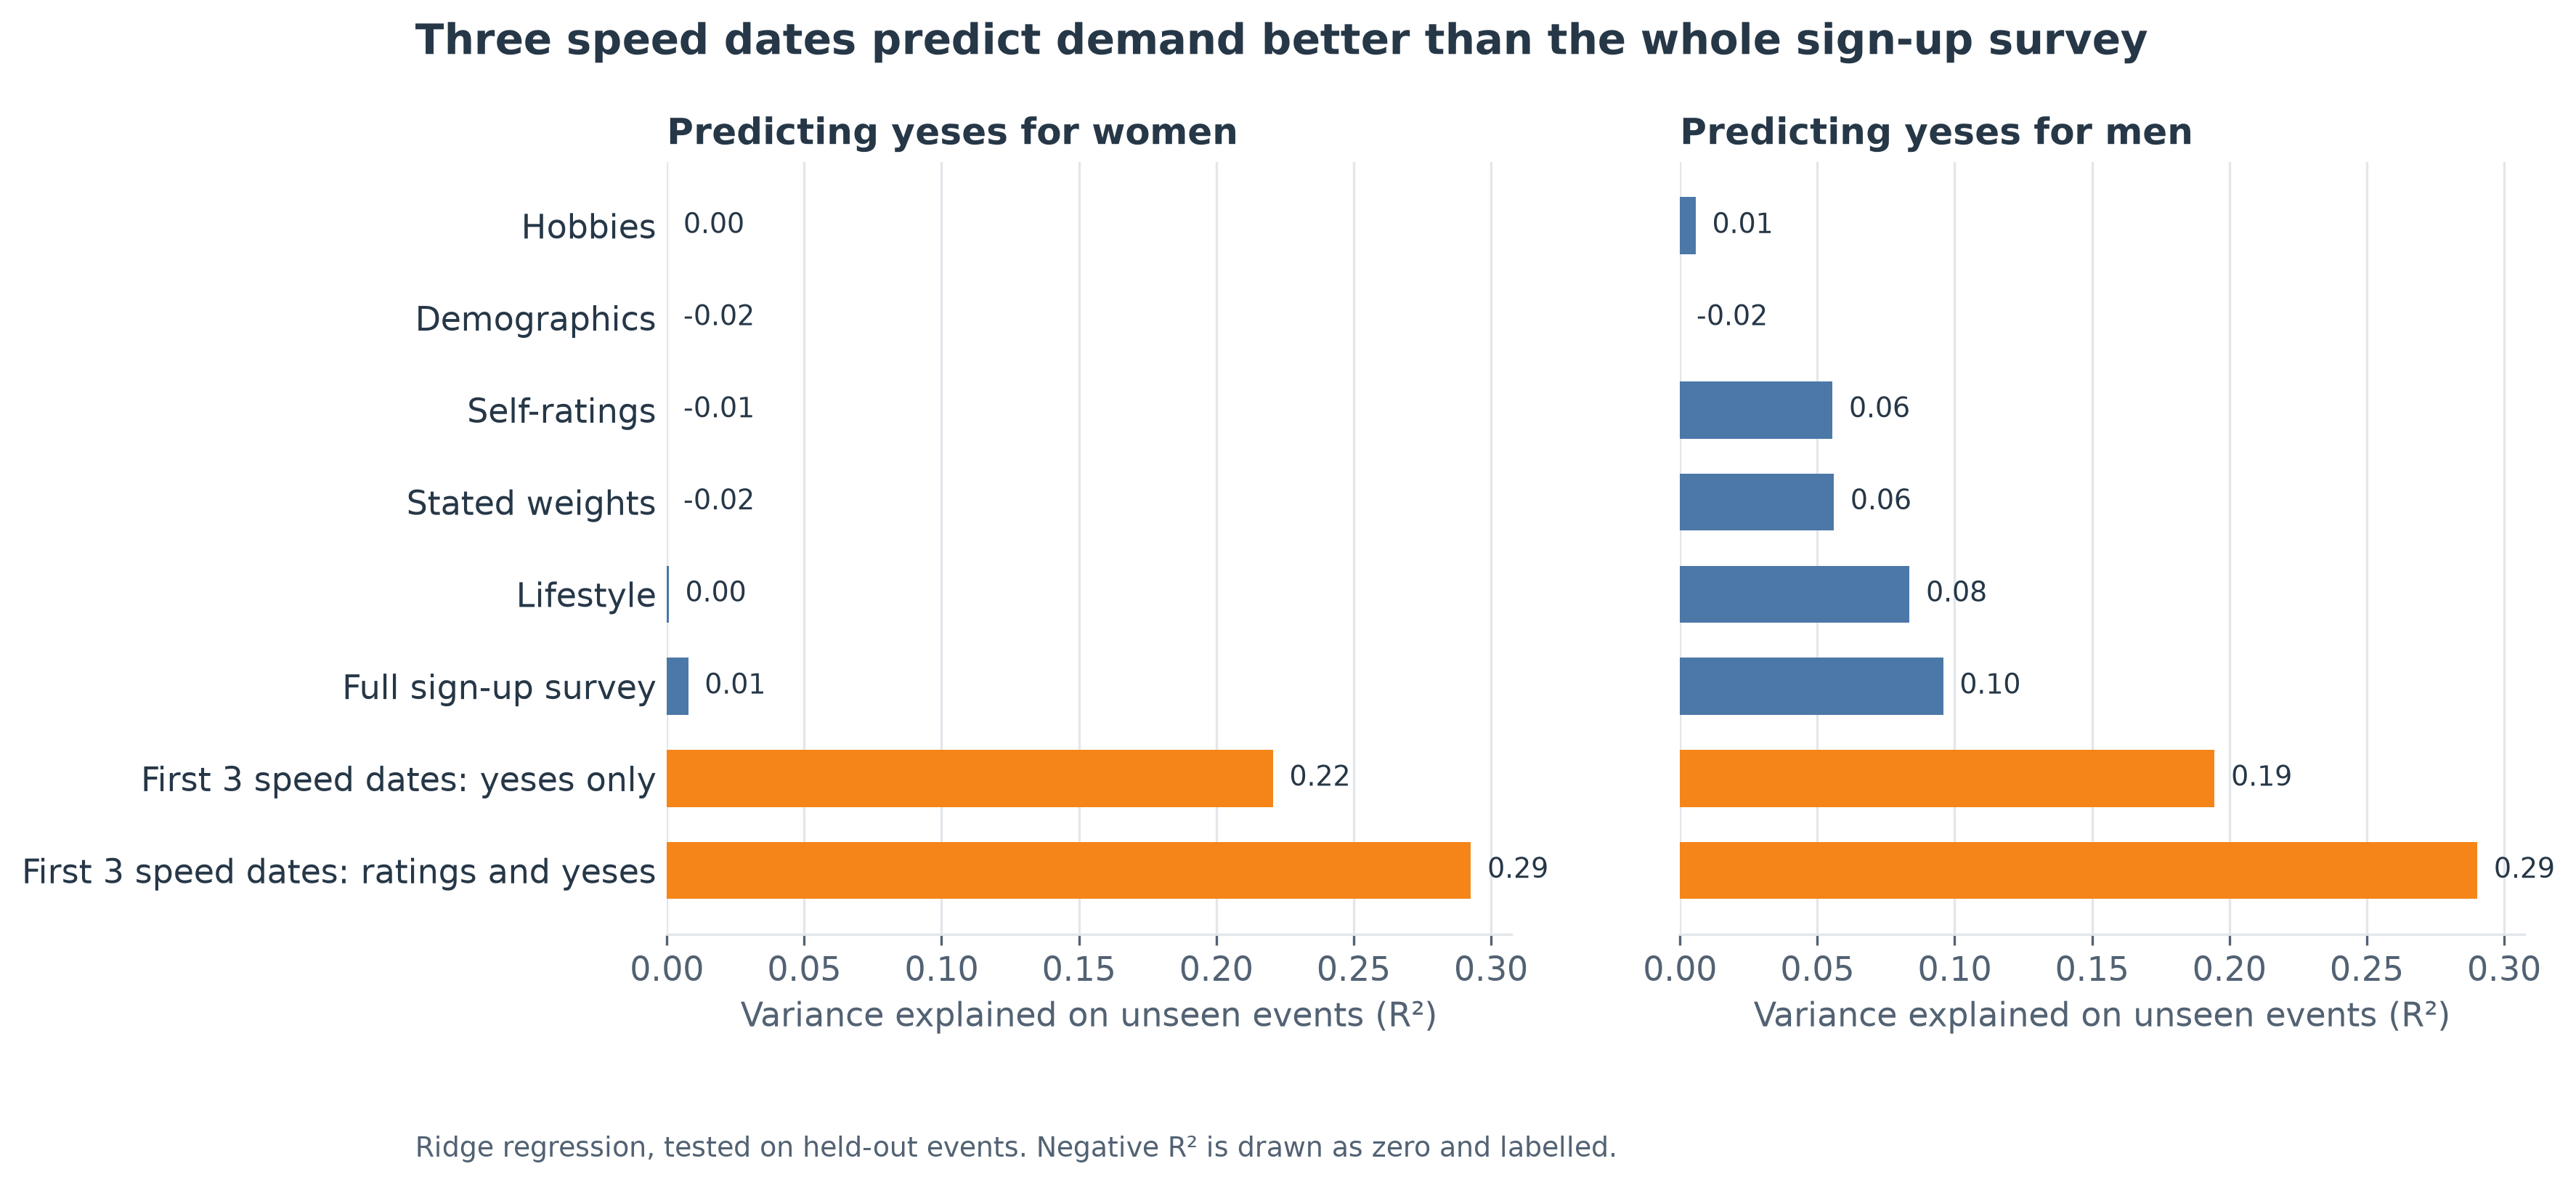

In [6]:
chart("ext_a3_survey_vs_behaviour.png")

In [7]:
for name in ["a3_prediction", "a3_r2_gap", "a3_pre_event"]:
    print(name)
    display(show(name))

a3_prediction


,people_rated,predictors,people,r2_ridge,r2_boosting
0,Women,Demographics,274,-0.023,-0.013
1,Women,Hobbies,274,-0.004,-0.052
2,Women,Stated weights,274,-0.016,-0.103
3,Women,Self-ratings,274,-0.015,-0.097
4,Women,Lifestyle,274,0.001,-0.093
5,Women,Full sign-up survey,274,0.008,-0.026
6,Women,First 3 speed dates: yeses only,274,0.221,0.230
7,Women,First 3 speed dates: ratings and yeses,274,0.293,0.247
8,Men,Demographics,277,-0.022,-0.043
9,Men,Hobbies,277,0.006,0.011


a3_r2_gap


,people_rated,r2_gap,ci_low,ci_high,p
0,Women,0.285,0.188,0.384,0.001
1,Men,0.194,0.100,0.279,0.001


a3_pre_event


,model,pairs,auc,top_decile_match_rate,base_rate,top_decile_lift,lift_ci_low,lift_ci_high
0,Pair facts only,4184,0.538,0.206,0.165,1.248,1.011,1.487
1,"All pre-event, logistic",4184,0.575,0.215,0.165,1.307,1.049,1.617
2,"All pre-event, boosting",4184,0.558,0.211,0.165,1.277,1.062,1.580


## A4. Do customers understand the market?

What people think others want, how well they guess a partner's answer, and how they think they are seen. `prob` is only ever an outcome here, never a predictor of `dec`.

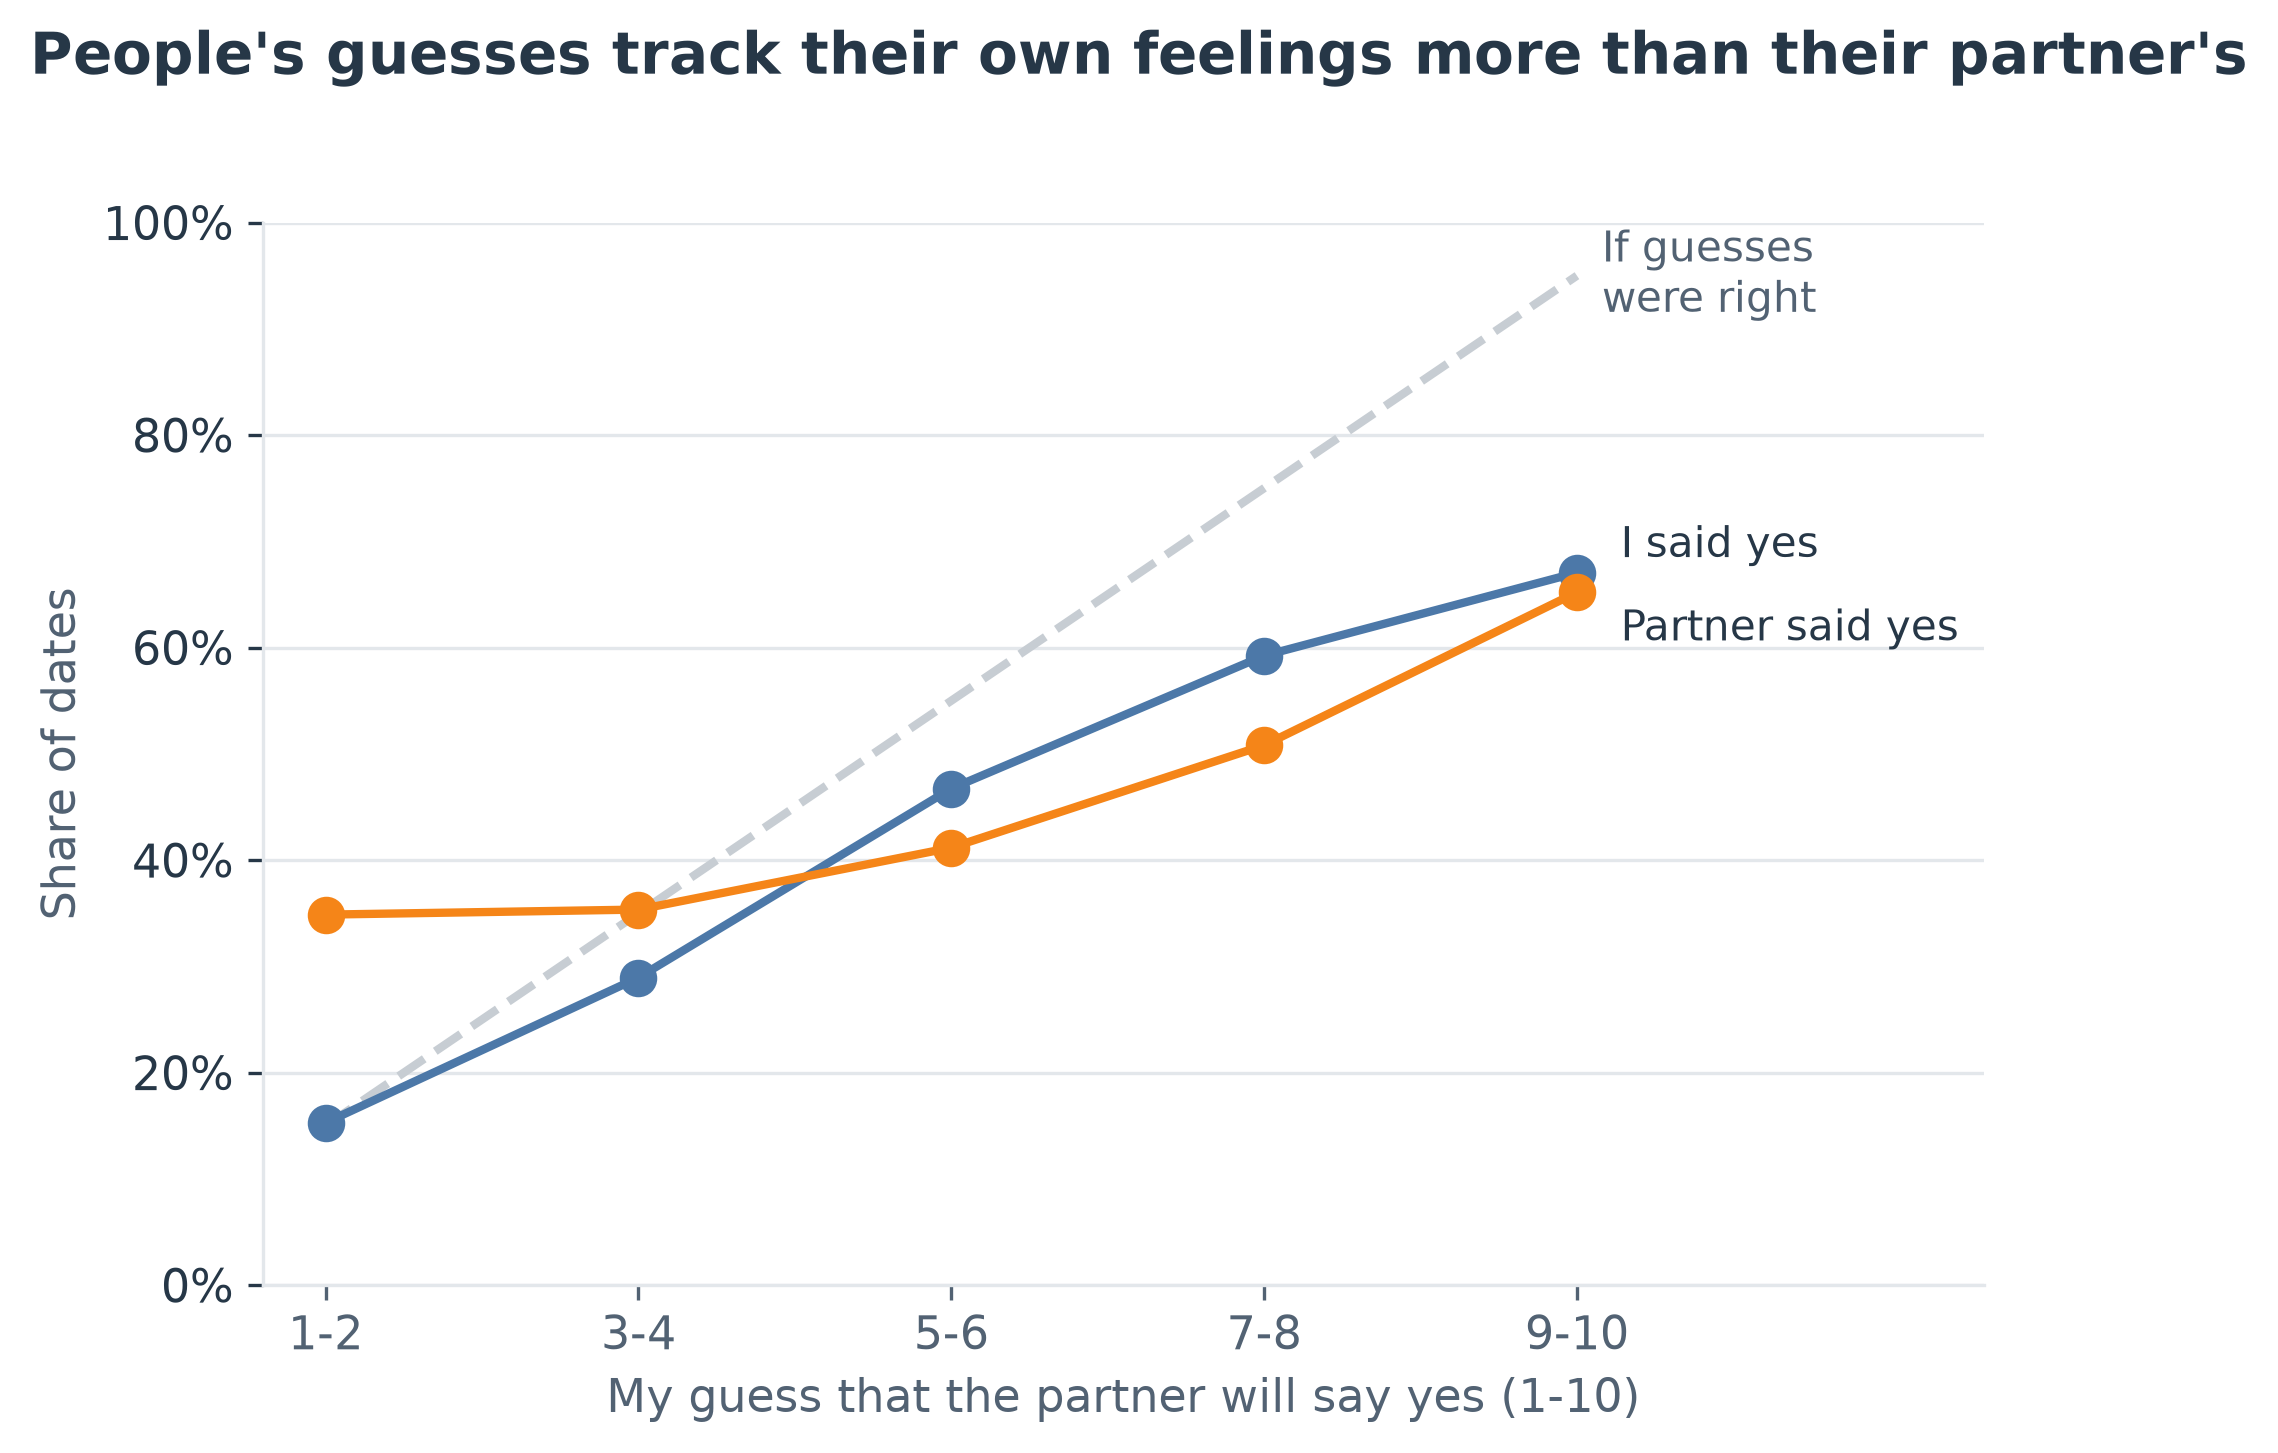

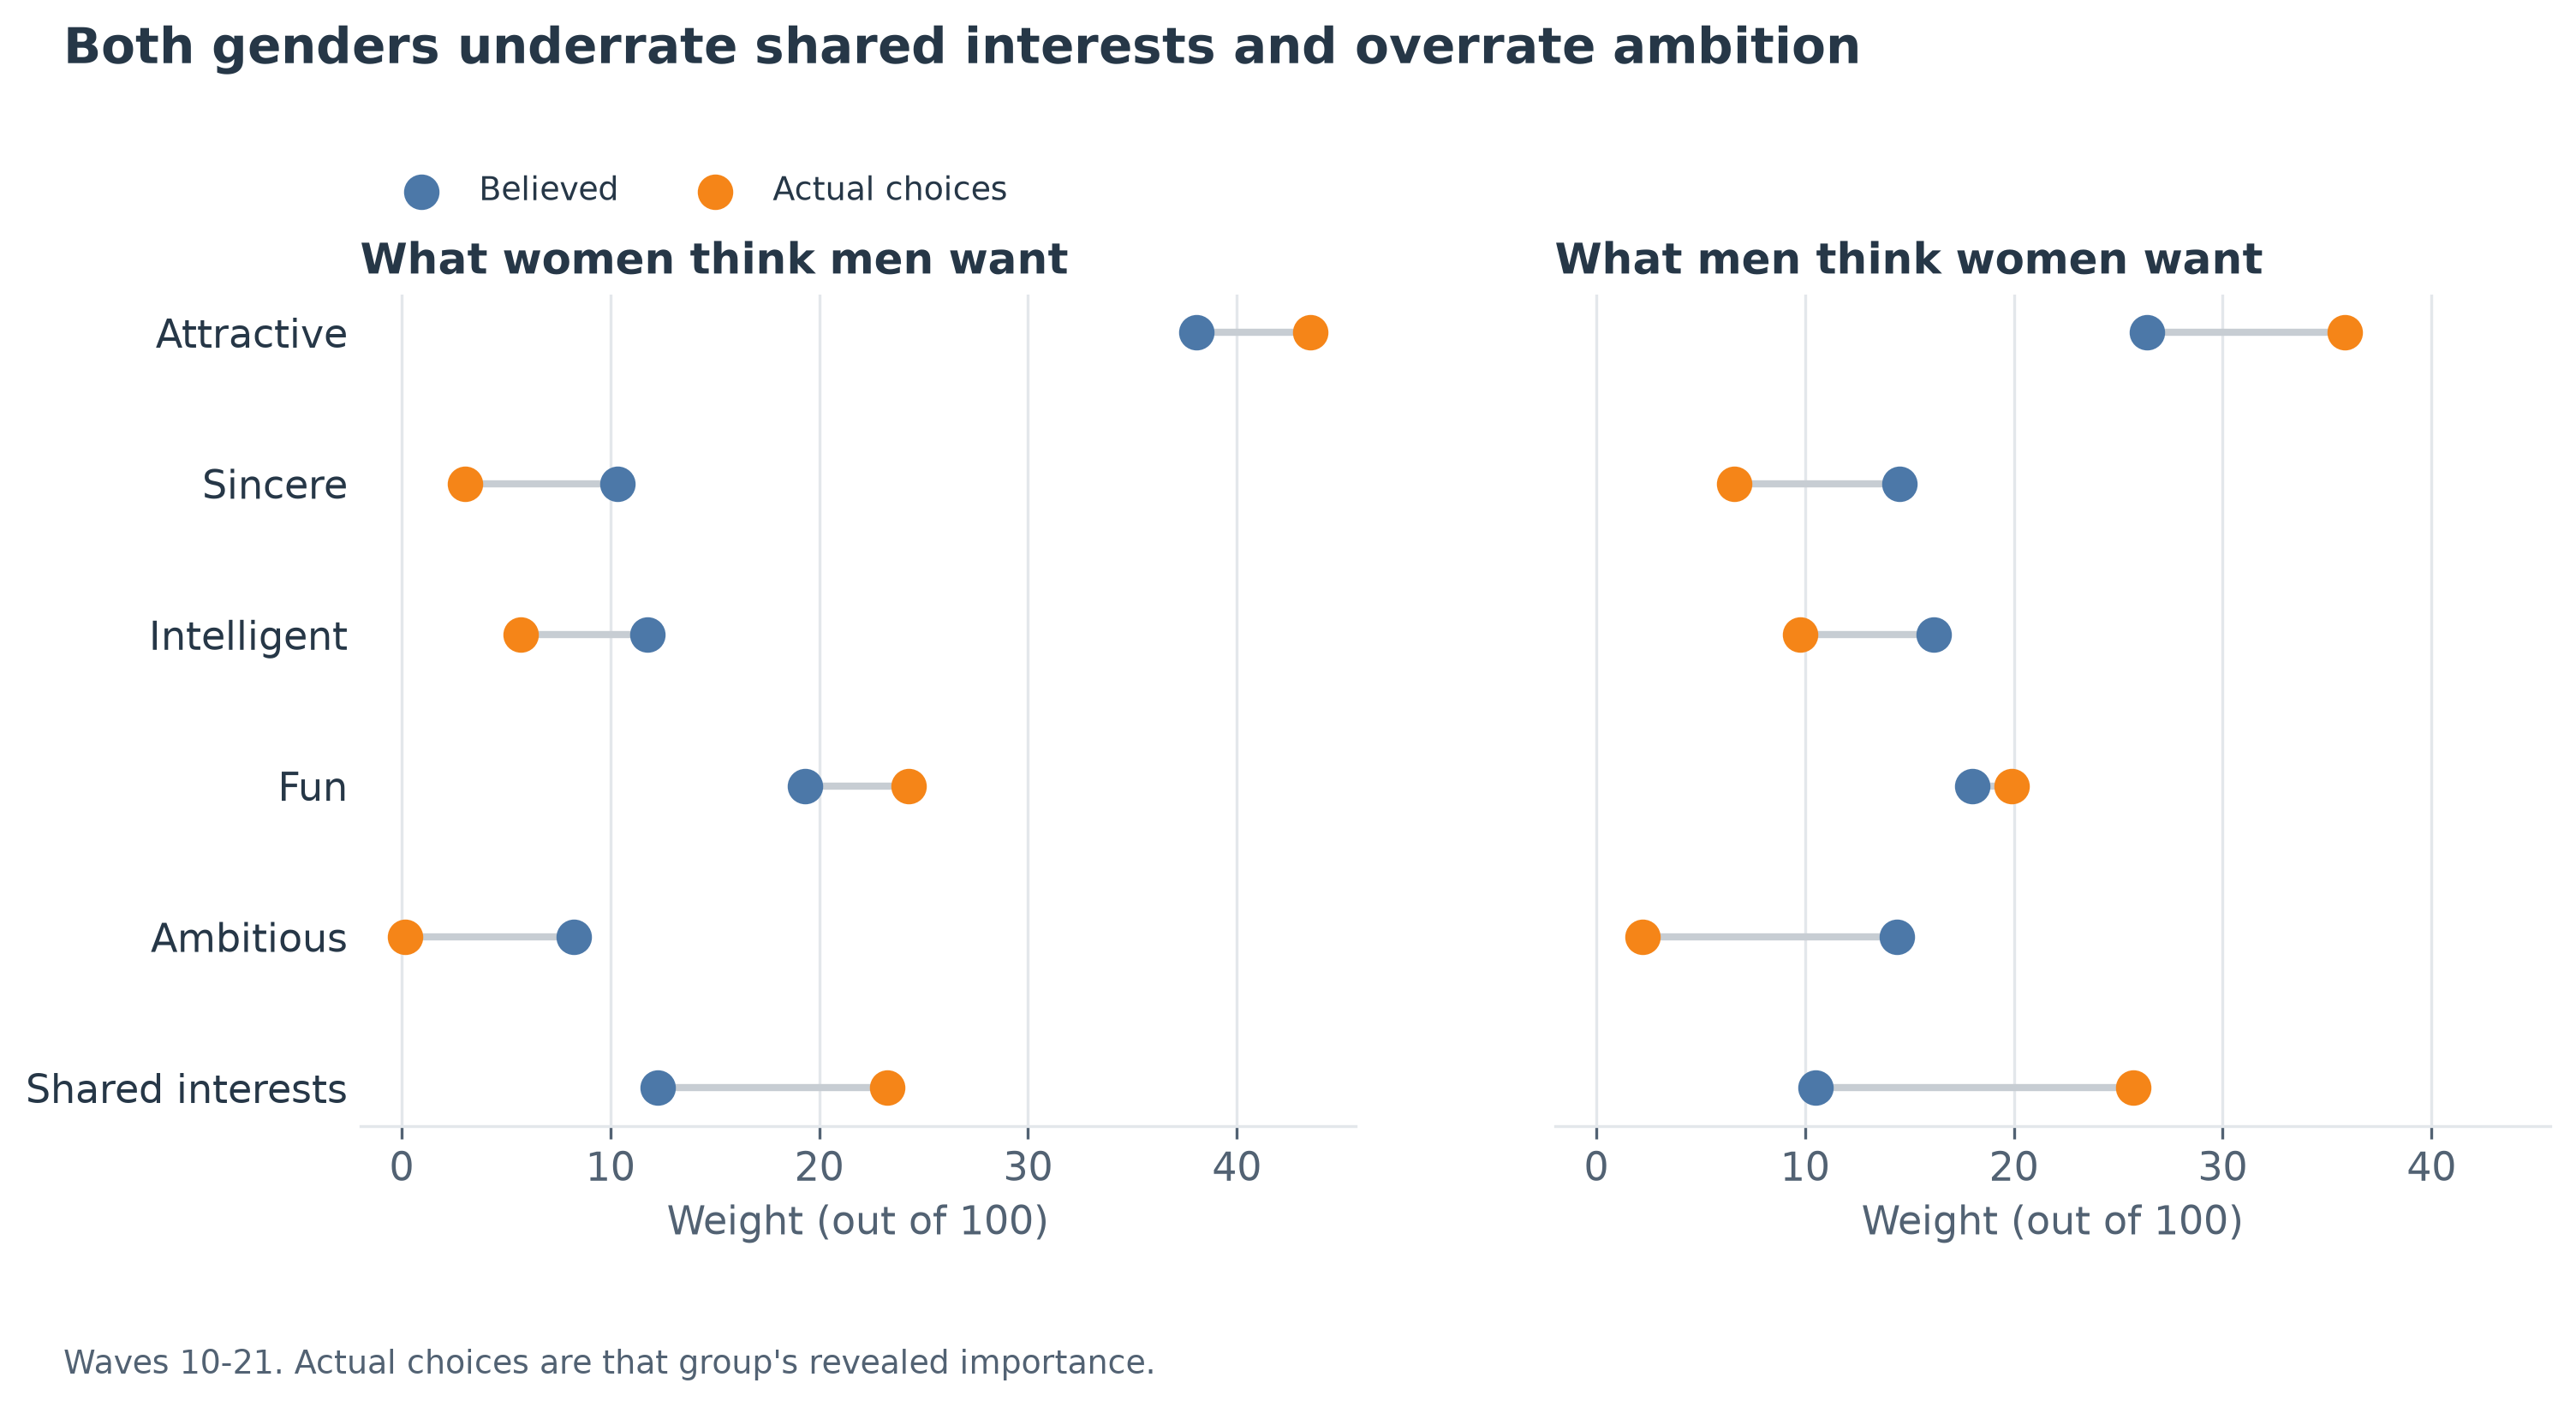

In [8]:
chart("ext_a4_calibration.png")
chart("ext_a4_beliefs.png")

In [9]:
for name in ["a4_beliefs", "a4_calibration", "a4_calibration_bins", "a4_optimism", "a4_self_image", "a4_belief_effects"]:
    print(name)
    display(show(name))

a4_beliefs


,believer,attribute,believed,choosers_actual,gap,gap_ci_low,gap_ci_high,choosers
0,Women,Attractive,38.061,43.527,5.466,-1.856,11.565,Men
1,Women,Sincere,10.348,3.025,-7.323,-10.984,-1.552,Men
2,Women,Intelligent,11.776,5.712,-6.064,-11.673,-0.485,Men
3,Women,Fun,19.311,24.301,4.991,-0.441,10.204,Men
4,Women,Ambitious,8.233,0.184,-8.049,-8.988,-2.438,Men
5,Women,Shared interests,12.272,23.250,10.978,4.479,15.818,Men
6,Men,Attractive,26.384,35.845,9.461,3.745,15.104,Women
7,Men,Sincere,14.540,6.610,-7.930,-14.336,-2.172,Women
8,Men,Intelligent,16.172,9.754,-6.419,-11.519,-0.586,Women
9,Men,Fun,18.006,19.874,1.868,-4.831,7.977,Women


a4_calibration


,measure,value,ci_low,ci_high,p
0,AUC: guess vs partner's real answer,0.585,0.067,0.102,0.001
1,AUC: guess vs own decision,0.679,0.156,0.202,0.001
2,AUC gap: own decision minus partner's answer,0.094,0.065,0.127,0.001
3,Brier score of guesses,0.267,0.260,0.274,0.001
4,Brier score of predicting the average,0.245,0.241,0.247,0.001
5,Brier gap: guesses minus average (positive is worse),0.022,0.015,0.031,0.001


a4_calibration_bins


,prob,rows,partner_said_yes,i_said_yes
0,"(0, 2]",955,0.349,0.153
1,"(2, 4]",1641,0.353,0.289
2,"(4, 6]",3199,0.412,0.467
3,"(6, 8]",1791,0.508,0.592
4,"(8, 10]",434,0.652,0.671


... (2 outputs left out)

a4_self_image


,question,attribute,people,believed,received,share_overrating,correlation,corr_ci_low,corr_ci_high
0,How I think others see me,Attractive,314,6.930,6.149,0.682,0.271,0.161,0.380
1,How I think others see me,Sincere,314,7.933,7.181,0.694,0.065,-0.043,0.179
2,How I think others see me,Intelligent,314,8.258,7.358,0.761,0.038,-0.076,0.144
3,How I think others see me,Fun,314,7.385,6.408,0.704,0.278,0.164,0.386
4,How I think others see me,Ambitious,314,7.602,6.770,0.685,0.132,0.005,0.249
5,How I rate myself,Attractive,542,7.092,6.199,0.732,0.288,0.201,0.368
6,How I rate myself,Sincere,542,8.286,7.225,0.768,-0.011,-0.084,0.063
7,How I rate myself,Intelligent,542,8.386,7.402,0.797,0.054,-0.033,0.139
8,How I rate myself,Fun,542,7.701,6.440,0.788,0.279,0.190,0.365
9,How I rate myself,Ambitious,542,7.577,6.825,0.692,0.158,0.072,0.240


a4_belief_effects


,outcome,people,believed_attractiveness,p,actual_attractiveness,actual_p
0,Own yes rate,314,-0.009,0.303,-0.064,0.000
1,Match rate,314,-0.006,0.145,0.049,0.000
2,Matches expected,299,0.196,0.017,0.005,0.969
3,Satisfaction,273,0.021,0.801,-0.120,0.229


## A5. Which metric should I optimise?

Ranking with pre-date information on unseen events. `a5_seed_sensitivity` shows how much the lift moves with the random split, and `a5_history_design` is the stricter independent test. Read the two together.

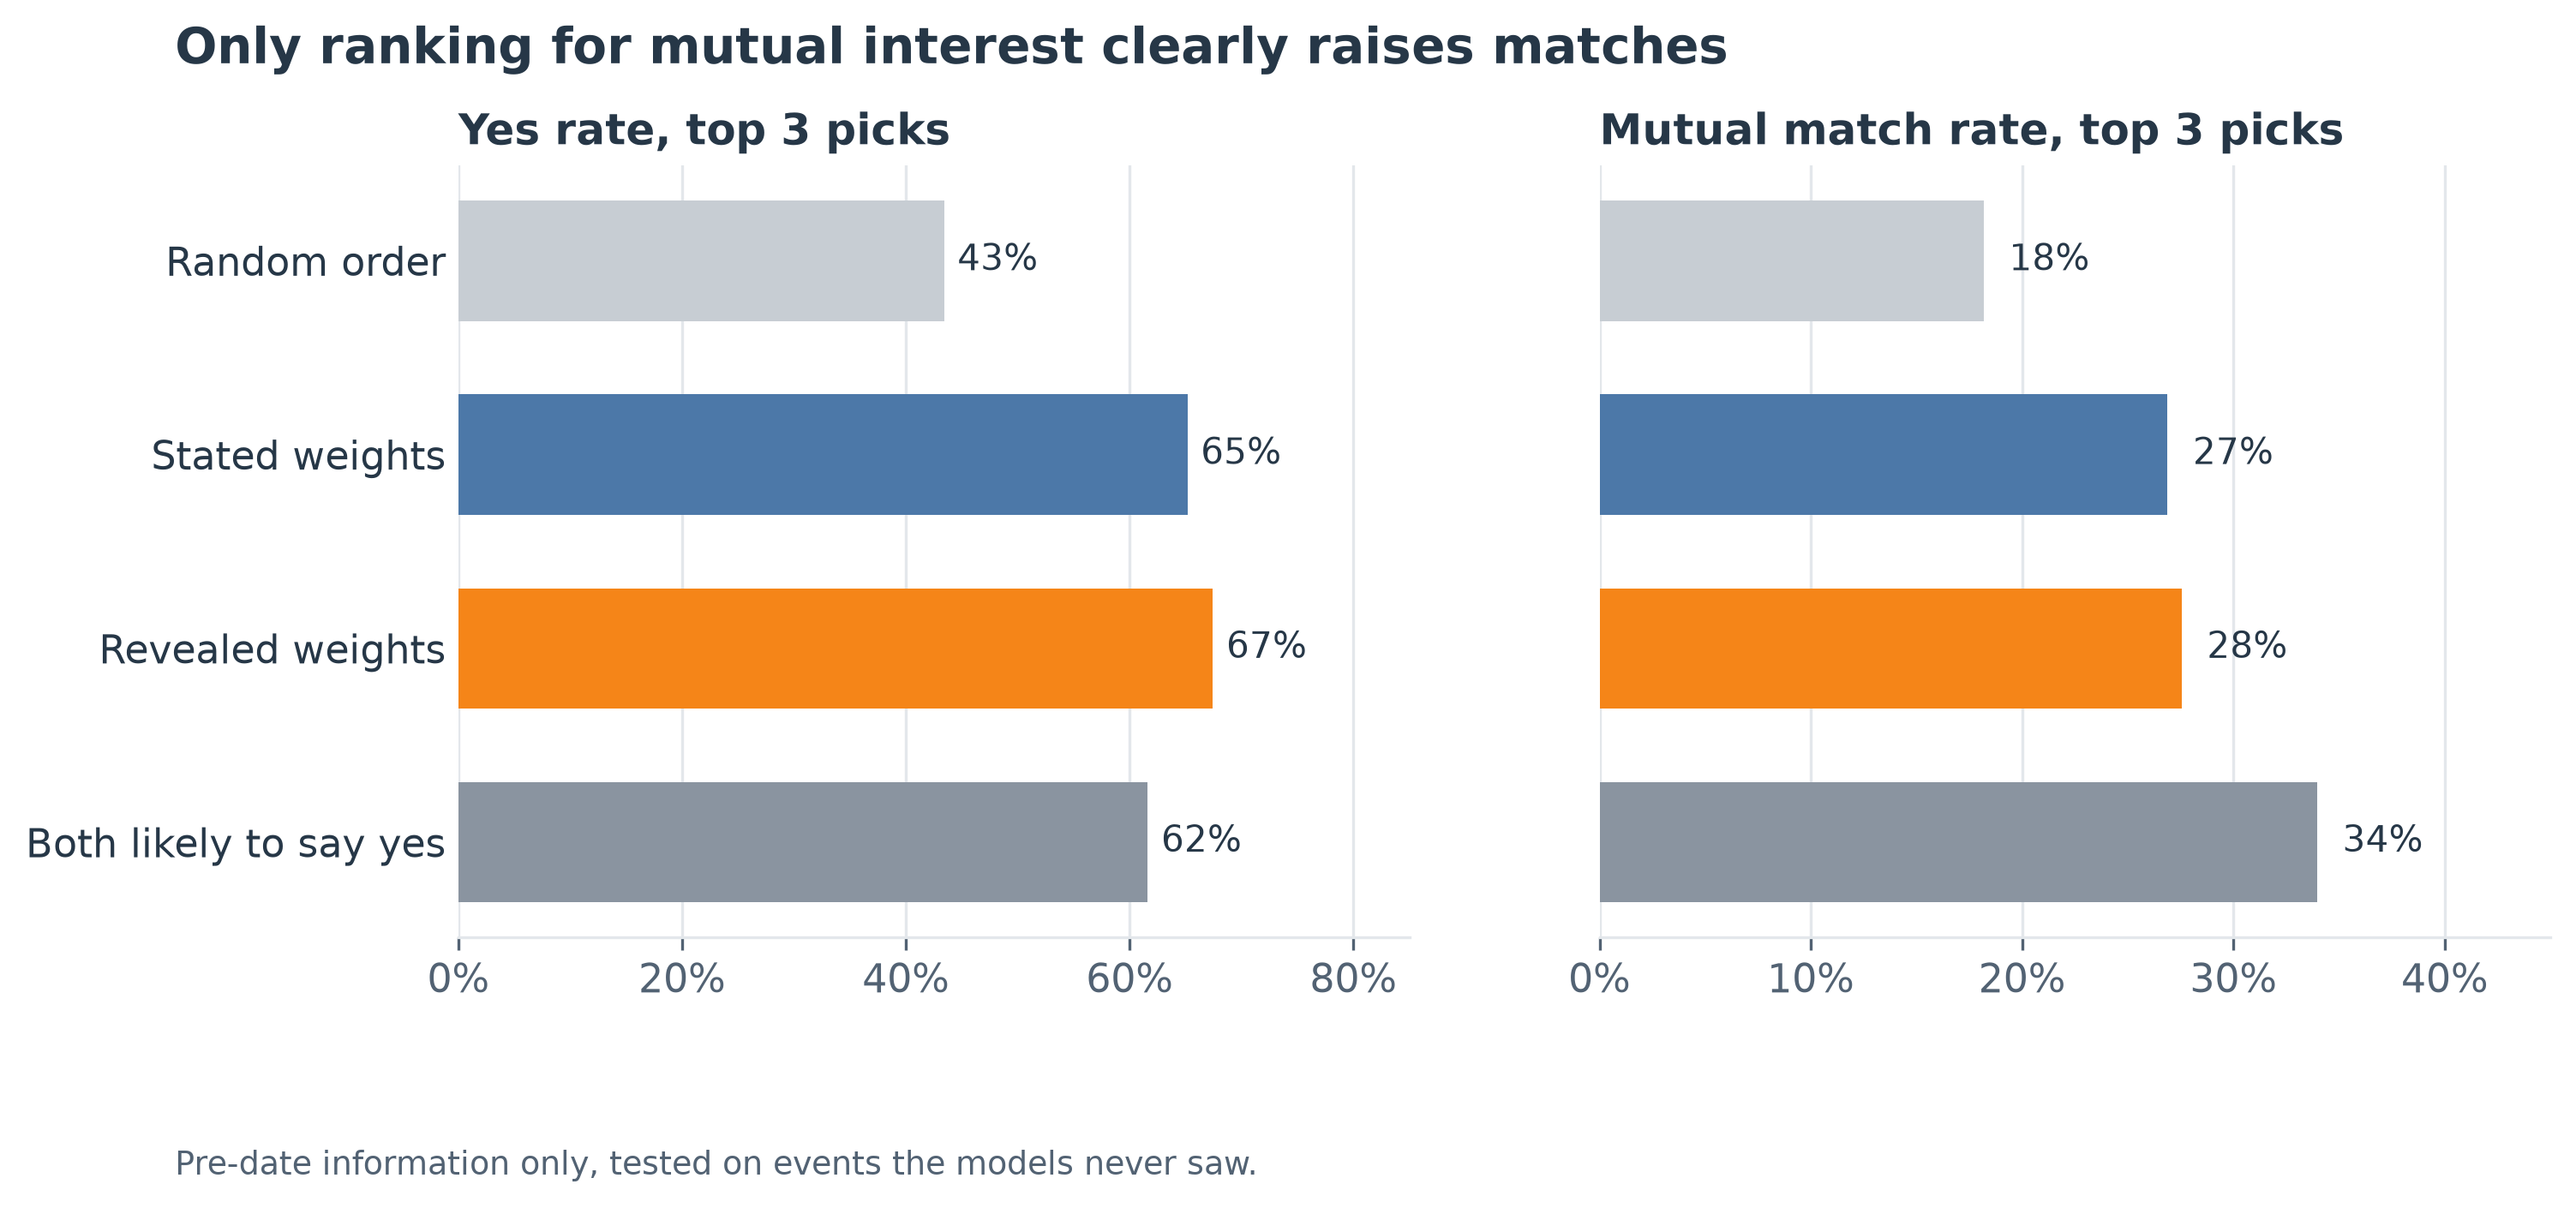

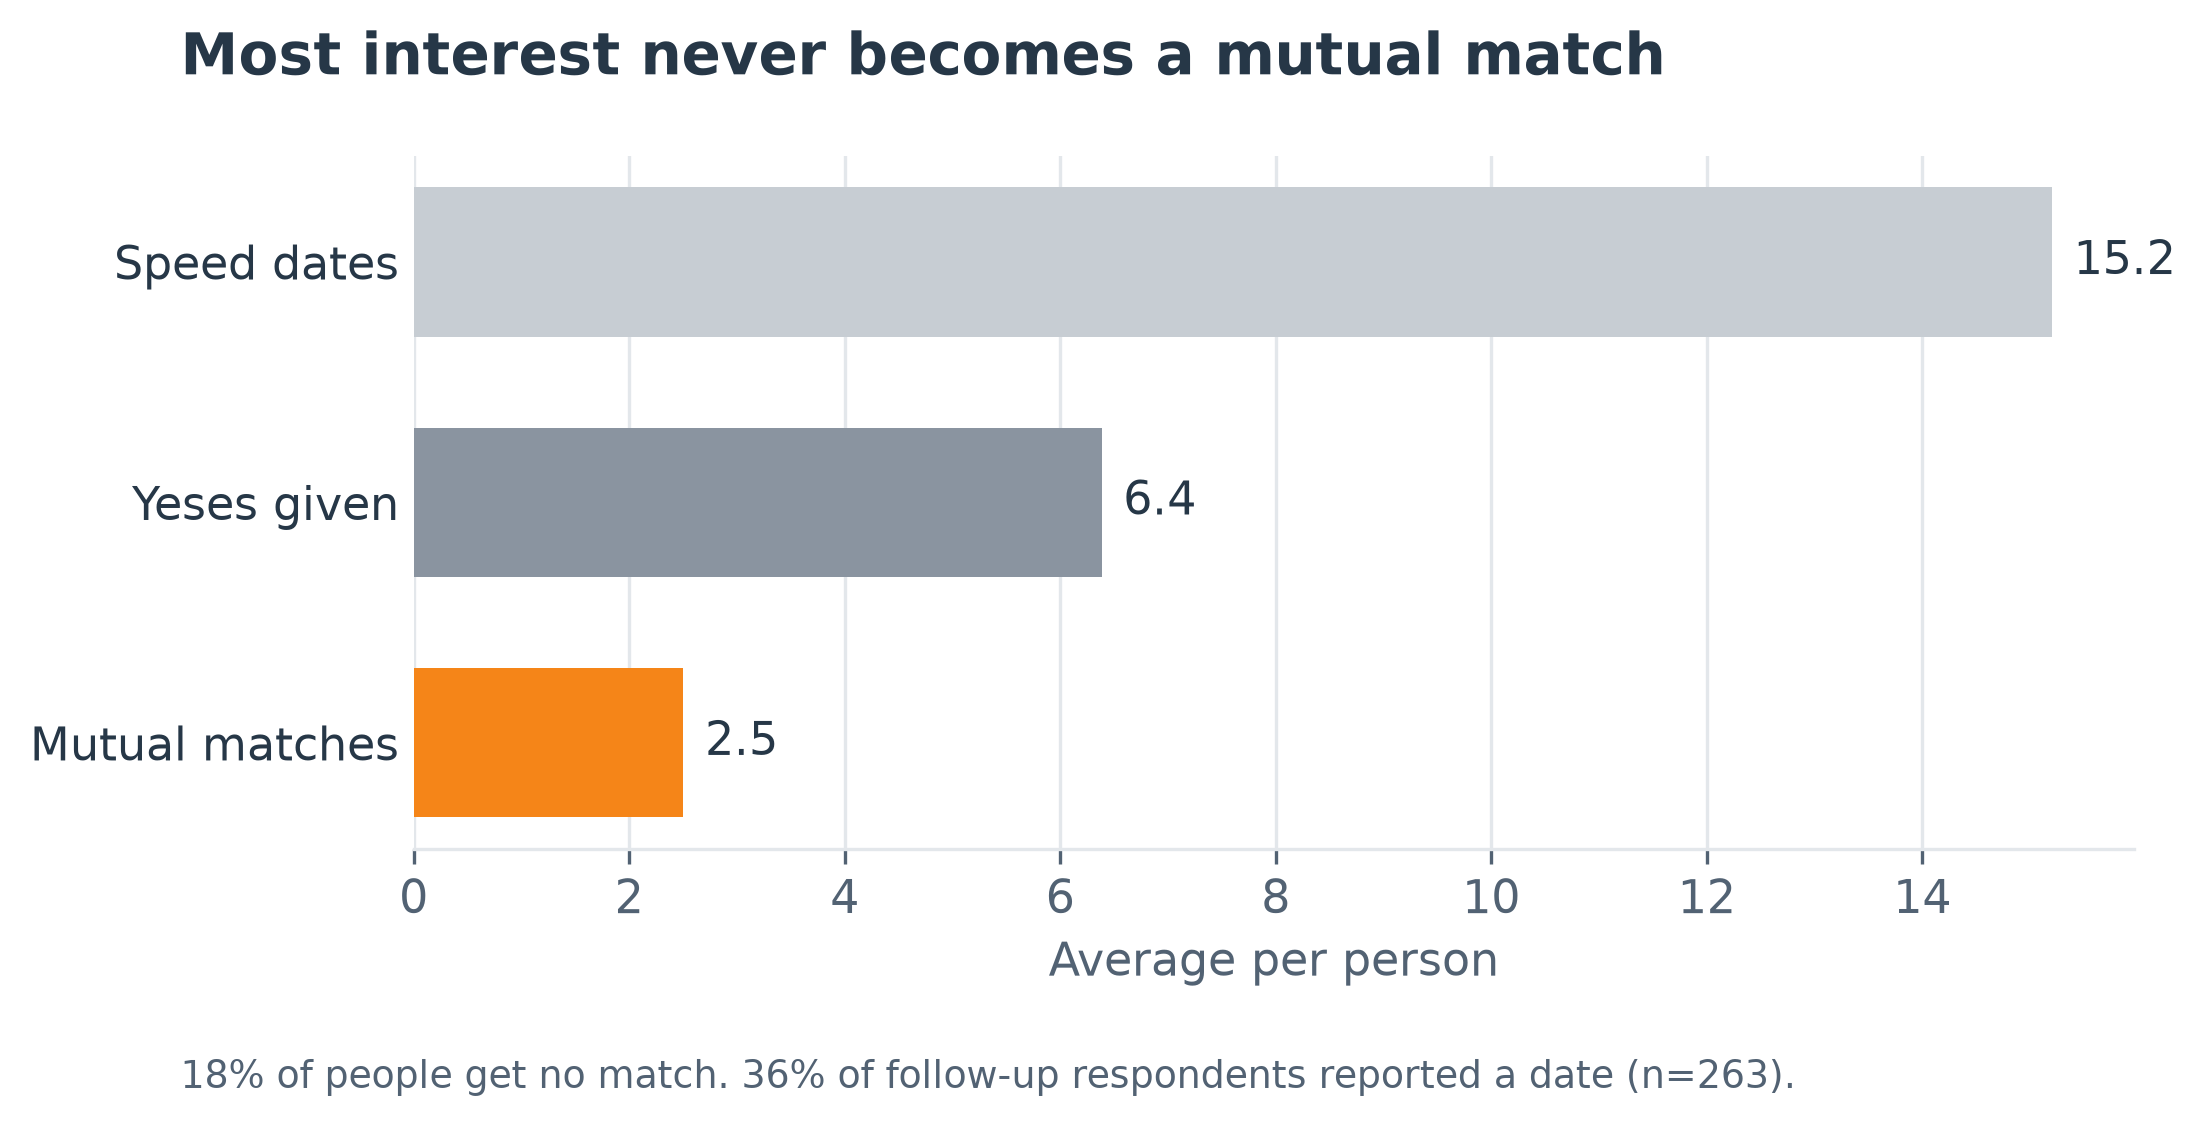

In [10]:
chart("ext_a5_yes_vs_match.png")
chart("ext_a5_funnel.png")

In [11]:
for name in ["a5_ranking", "a5_lifts", "a5_seed_sensitivity", "a5_partner_model", "a5_history_design", "a5_exposure", "a5_who_benefits", "a5_funnel"]:
    print(name)
    display(show(name))

a5_ranking


,top_k,rule,yes_rate,match_rate,partner_yes_rate,no_match_share
0,1,Random order,0.434,0.197,0.458,0.803
1,3,Random order,0.434,0.182,0.437,0.558
2,5,Random order,0.440,0.192,0.451,0.372
3,1,Stated weights,0.717,0.299,0.412,0.701
4,3,Stated weights,0.652,0.269,0.412,0.431
5,5,Stated weights,0.602,0.248,0.411,0.321
6,1,Revealed weights,0.739,0.277,0.369,0.723
7,3,Revealed weights,0.674,0.275,0.405,0.431
8,5,Revealed weights,0.613,0.245,0.399,0.314
9,1,Revealed + pair facts,0.761,0.294,0.381,0.706


a5_lifts


,top_k,comparison,metric,lift_pp,ci_low,ci_high,p
0,1,Revealed weights minus Stated weights,Yes rate,2.212,-1.549,6.416,0.245
1,1,Revealed weights minus Stated weights,Match rate,-2.212,-5.973,1.549,0.259
2,1,Both likely to say yes minus Stated weights,Yes rate,-7.301,-11.947,-2.655,0.001
3,1,Both likely to say yes minus Stated weights,Match rate,9.956,5.304,14.602,0.001
4,1,Both likely to say yes minus Revealed weights,Yes rate,-9.513,-14.381,-4.646,0.001
5,1,Both likely to say yes minus Revealed weights,Match rate,12.168,7.522,17.035,0.001
6,1,"Revealed, post-date ratings minus Stated, post-date ratings",Yes rate,2.434,0.000,5.088,0.061
7,1,"Revealed, post-date ratings minus Stated, post-date ratings",Match rate,1.549,-1.991,4.867,0.415
8,3,Revealed weights minus Stated weights,Yes rate,2.286,0.588,4.058,0.013
9,3,Revealed weights minus Stated weights,Match rate,0.664,-1.032,2.286,0.413


a5_seed_sensitivity


,seed,stated_match,revealed_match,reciprocal_match,reciprocal_lift_pp,reciprocal_yes_cost_pp
0,42,0.269,0.275,0.340,7.080,-3.540
1,7,0.267,0.264,0.323,5.605,-4.056
2,123,0.267,0.262,0.318,5.088,-4.941
3,2024,0.266,0.262,0.323,5.678,-4.277
4,99,0.270,0.264,0.312,4.130,-5.015


... (6 outputs left out)

a5_who_benefits


,tier,rule,people,match_rate,no_match_share
0,Least chosen third,Stated weights,152,0.096,0.730
1,Least chosen third,Revealed weights,152,0.096,0.737
2,Least chosen third,Both likely to say yes,152,0.173,0.572
3,Middle third,Stated weights,155,0.276,0.368
4,Middle third,Revealed weights,155,0.266,0.413
5,Middle third,Both likely to say yes,155,0.369,0.265
6,Most chosen third,Stated weights,145,0.441,0.186
7,Most chosen third,Revealed weights,145,0.474,0.131
8,Most chosen third,Both likely to say yes,145,0.483,0.131


a5_funnel


,stage,value,people
0,Speed dates per person,15.205,551
1,Yeses given,6.385,551
2,Mutual matches,2.505,551
3,Share with no match,0.180,551
4,Answered the 3-4 week follow-up,0.477,551
5,Contacted a match,0.369,263
6,Was contacted,0.475,263
7,Went on a date with a match,0.357,263
8,Date rate if at least one match,0.416,226
9,Change in date chance per extra match,0.062,226


## A6. How much can personalisation do?

Unexplained includes both chemistry and random noise. `unexplained_low` and `unexplained_high` show the range when one event is dropped.

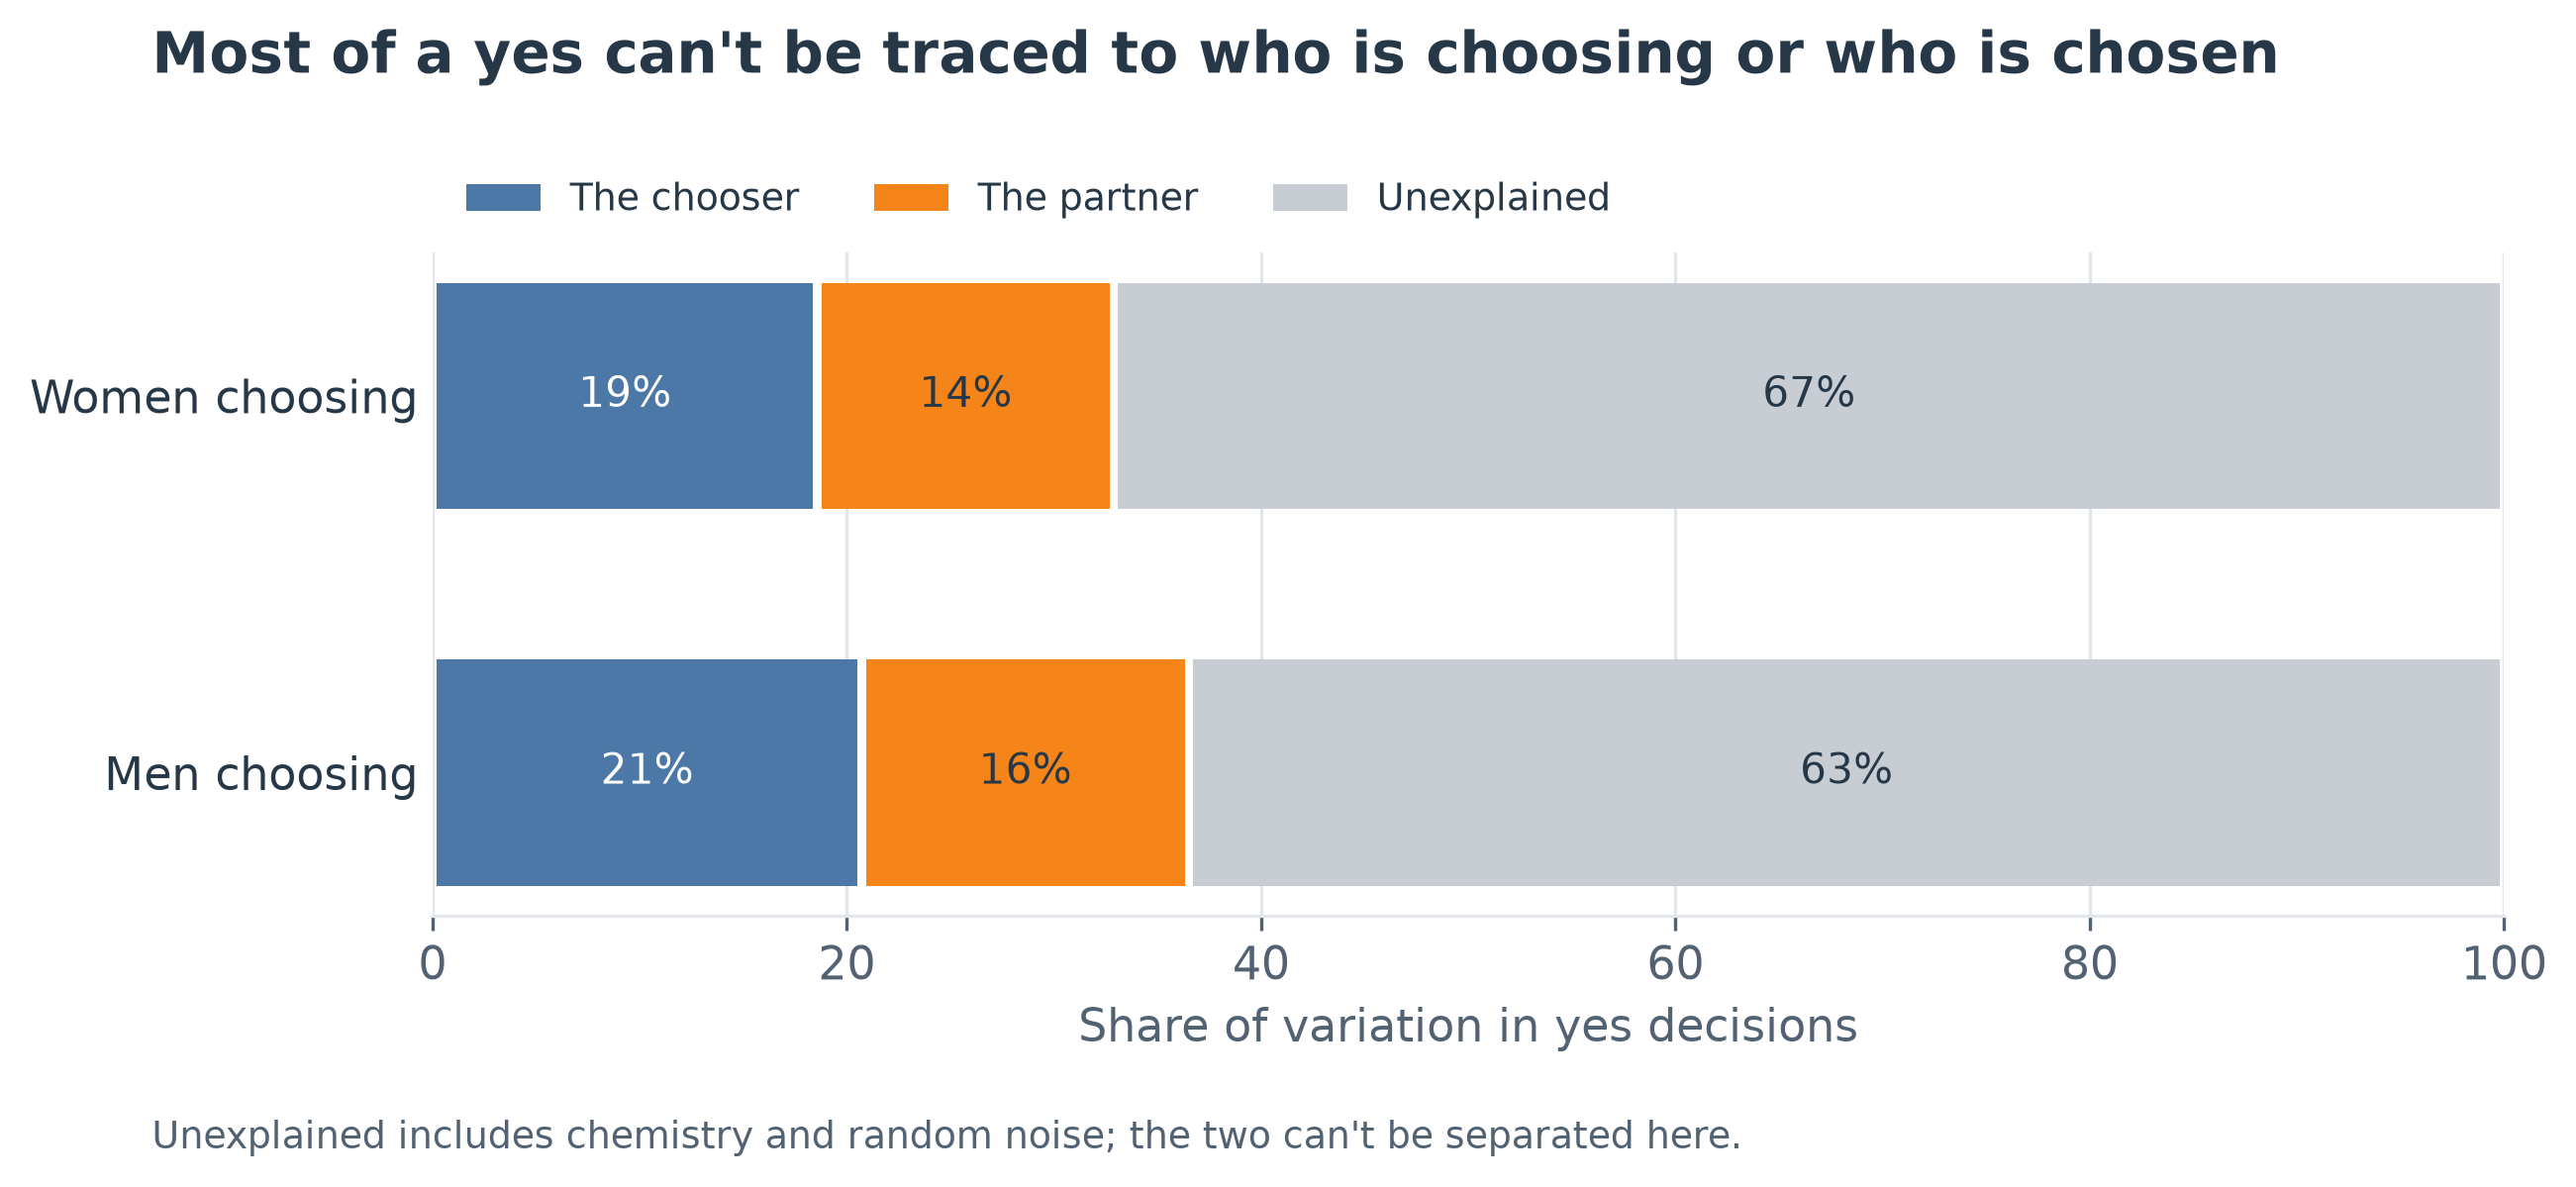

In [12]:
chart("ext_a6_variance.png")

In [13]:
for name in ["a6_variance"]:
    print(name)
    display(show(name))

a6_variance


,group,rows,chooser_share,partner_share,partner_alone,both,unexplained_share,unexplained_low,unexplained_high,pair_facts_held_out_r2,mutual_chemistry_correlation
0,Women choosing,4184,0.186,0.143,0.153,0.329,0.671,0.666,0.678,-0.002,0.103
1,Men choosing,4184,0.207,0.158,0.168,0.365,0.635,0.629,0.646,-0.002,0.103


## S1. Perceptual map

Each person placed by the ratings they received, with stated and revealed preferences as arrows. Colour shows yeses received. A segment-level version is not useful: see the last two columns of `s1_fit`.

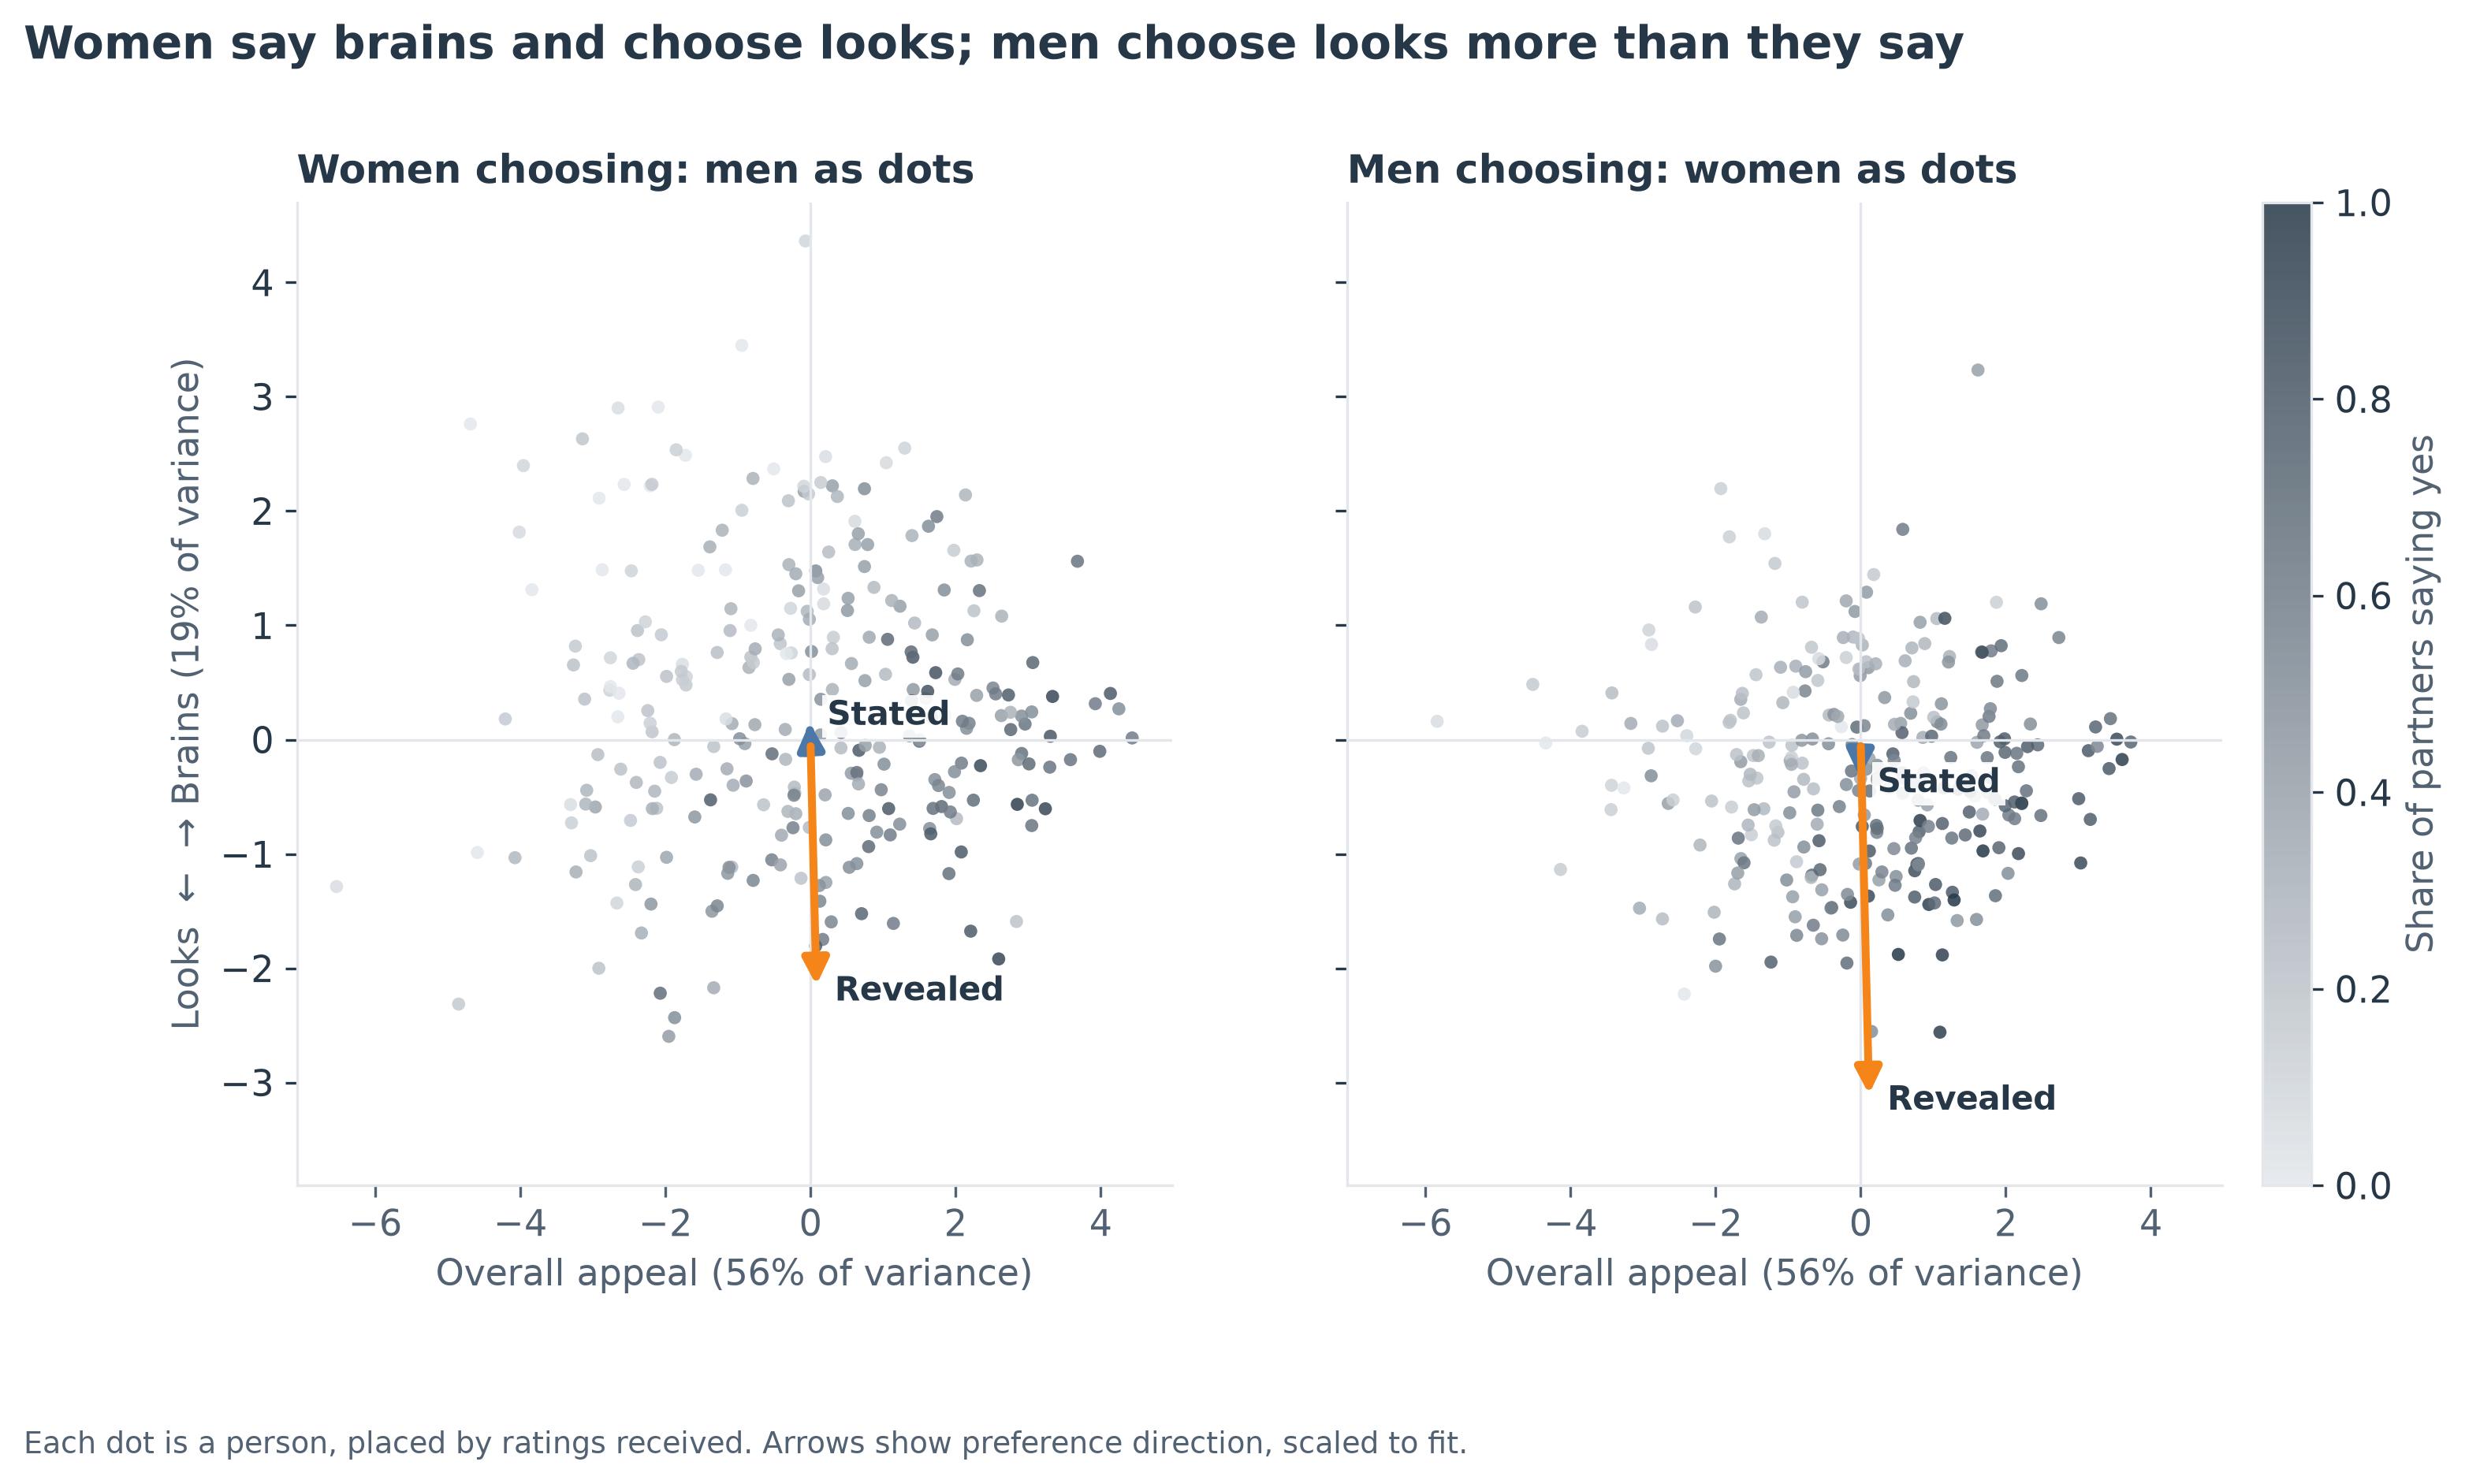

In [14]:
chart("ext_s1_perceptual_map.png")

In [15]:
for name in ["s1_axes", "s1_arrows", "s1_fit"]:
    print(name)
    display(show(name))

s1_axes


,axis,variance_share,Attractive,Sincere,Intelligent,Fun,Ambitious,Shared interests
0,Overall appeal,0.561,0.396,0.356,0.399,0.449,0.386,0.455
1,Brains vs looks,0.191,-0.470,0.418,0.540,-0.372,0.307,-0.285


s1_arrows


,gender,source,appeal,brains
0,Women,Stated,-0.207,2.274
1,Women,Revealed,0.928,-24.515
2,Men,Stated,-0.208,-4.273
3,Men,Revealed,1.310,-35.127


s1_fit


,people_rated,people,r2_attractive_only,r2_all_six,r2_two_axes,segment_share_of_appeal_axis,segment_share_of_brains_axis
0,Women,274,0.633,0.663,0.589,0.006,0.009
1,Men,277,0.599,0.651,0.614,0.006,0.009


## S2. Contrast effect (and N7)

Judge `excess_pp`, not the raw estimate: with person effects, a lagged yes is negative by construction, which is why every estimate is compared with shuffled order.

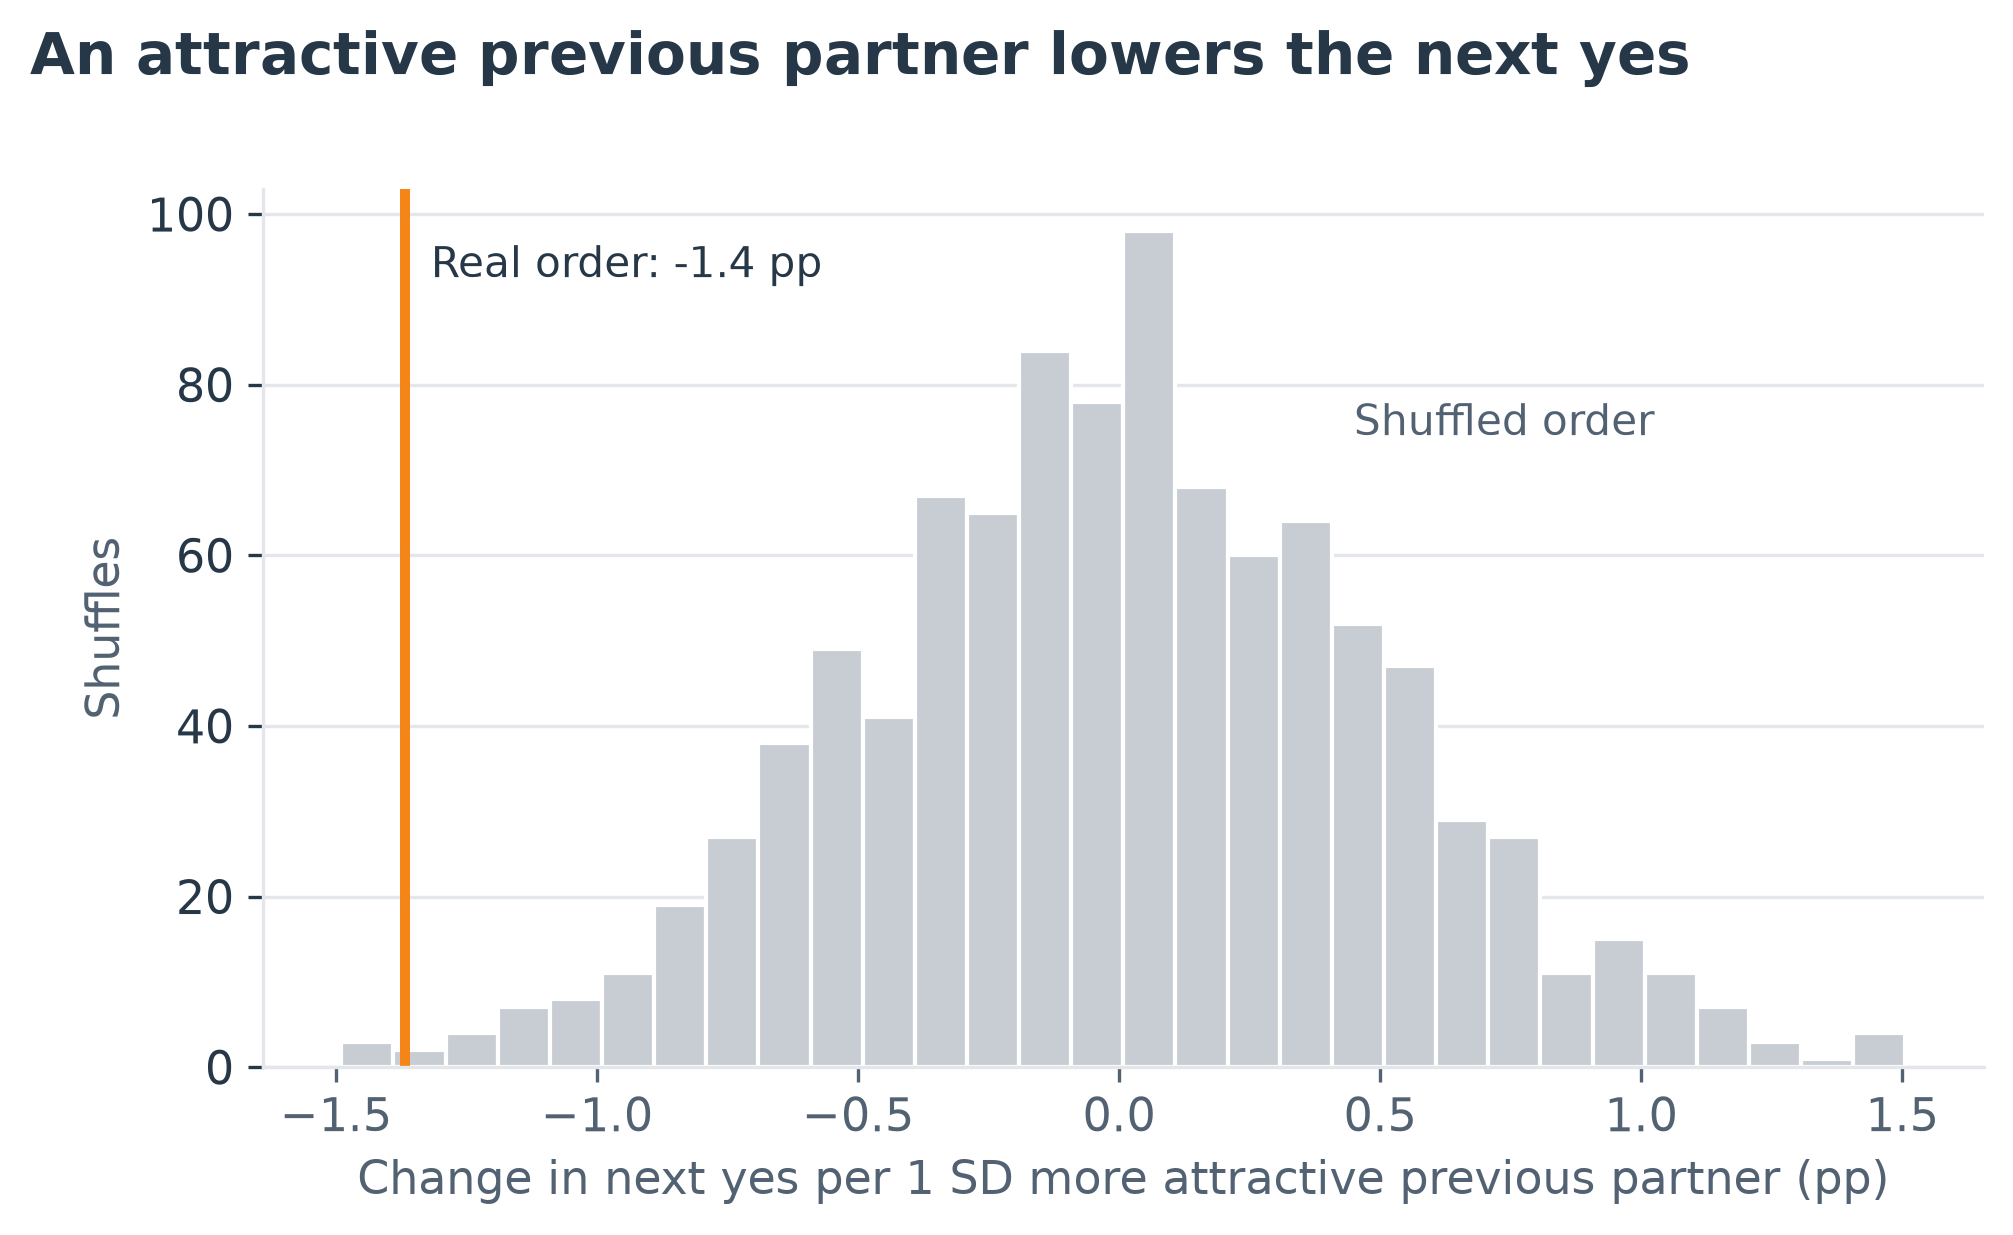

In [16]:
chart("ext_s2_contrast.png")

In [17]:
for name in ["s2_contrast"]:
    print(name)
    display(show(name))

s2_contrast


,group,effect,estimate_pp,placebo_mean_pp,excess_pp,placebo_p,rows,rating_change_per_sd,rating_change_p
0,Everyone,Previous partner's attractiveness,-1.368,0.003,-1.371,0.008,8368,-0.002,0.915
1,Everyone,"Same, holding previous decision fixed",-0.314,1.232,-1.547,0.003,8368,-0.002,0.915
2,Everyone,Previous decision was yes (N7),-5.776,-6.916,1.141,0.298,8368,-0.002,0.915
3,Women choosing,Previous partner's attractiveness,-0.824,-0.035,-0.790,0.287,4184,-0.002,0.915
4,Women choosing,"Same, holding previous decision fixed",0.352,1.093,-0.741,0.332,4184,-0.002,0.915
5,Women choosing,Previous decision was yes (N7),-7.008,-6.794,-0.214,0.883,4184,-0.002,0.915
6,Men choosing,Previous partner's attractiveness,-1.719,-0.024,-1.696,0.017,4184,-0.002,0.915
7,Men choosing,"Same, holding previous decision fixed",-0.863,1.231,-2.094,0.016,4184,-0.002,0.915
8,Men choosing,Previous decision was yes (N7),-4.538,-6.916,2.377,0.138,4184,-0.002,0.915


## S3. Market simulator

One or two exclusive recommendations each, on later-evening pairs. Intervals resample the 21 events.

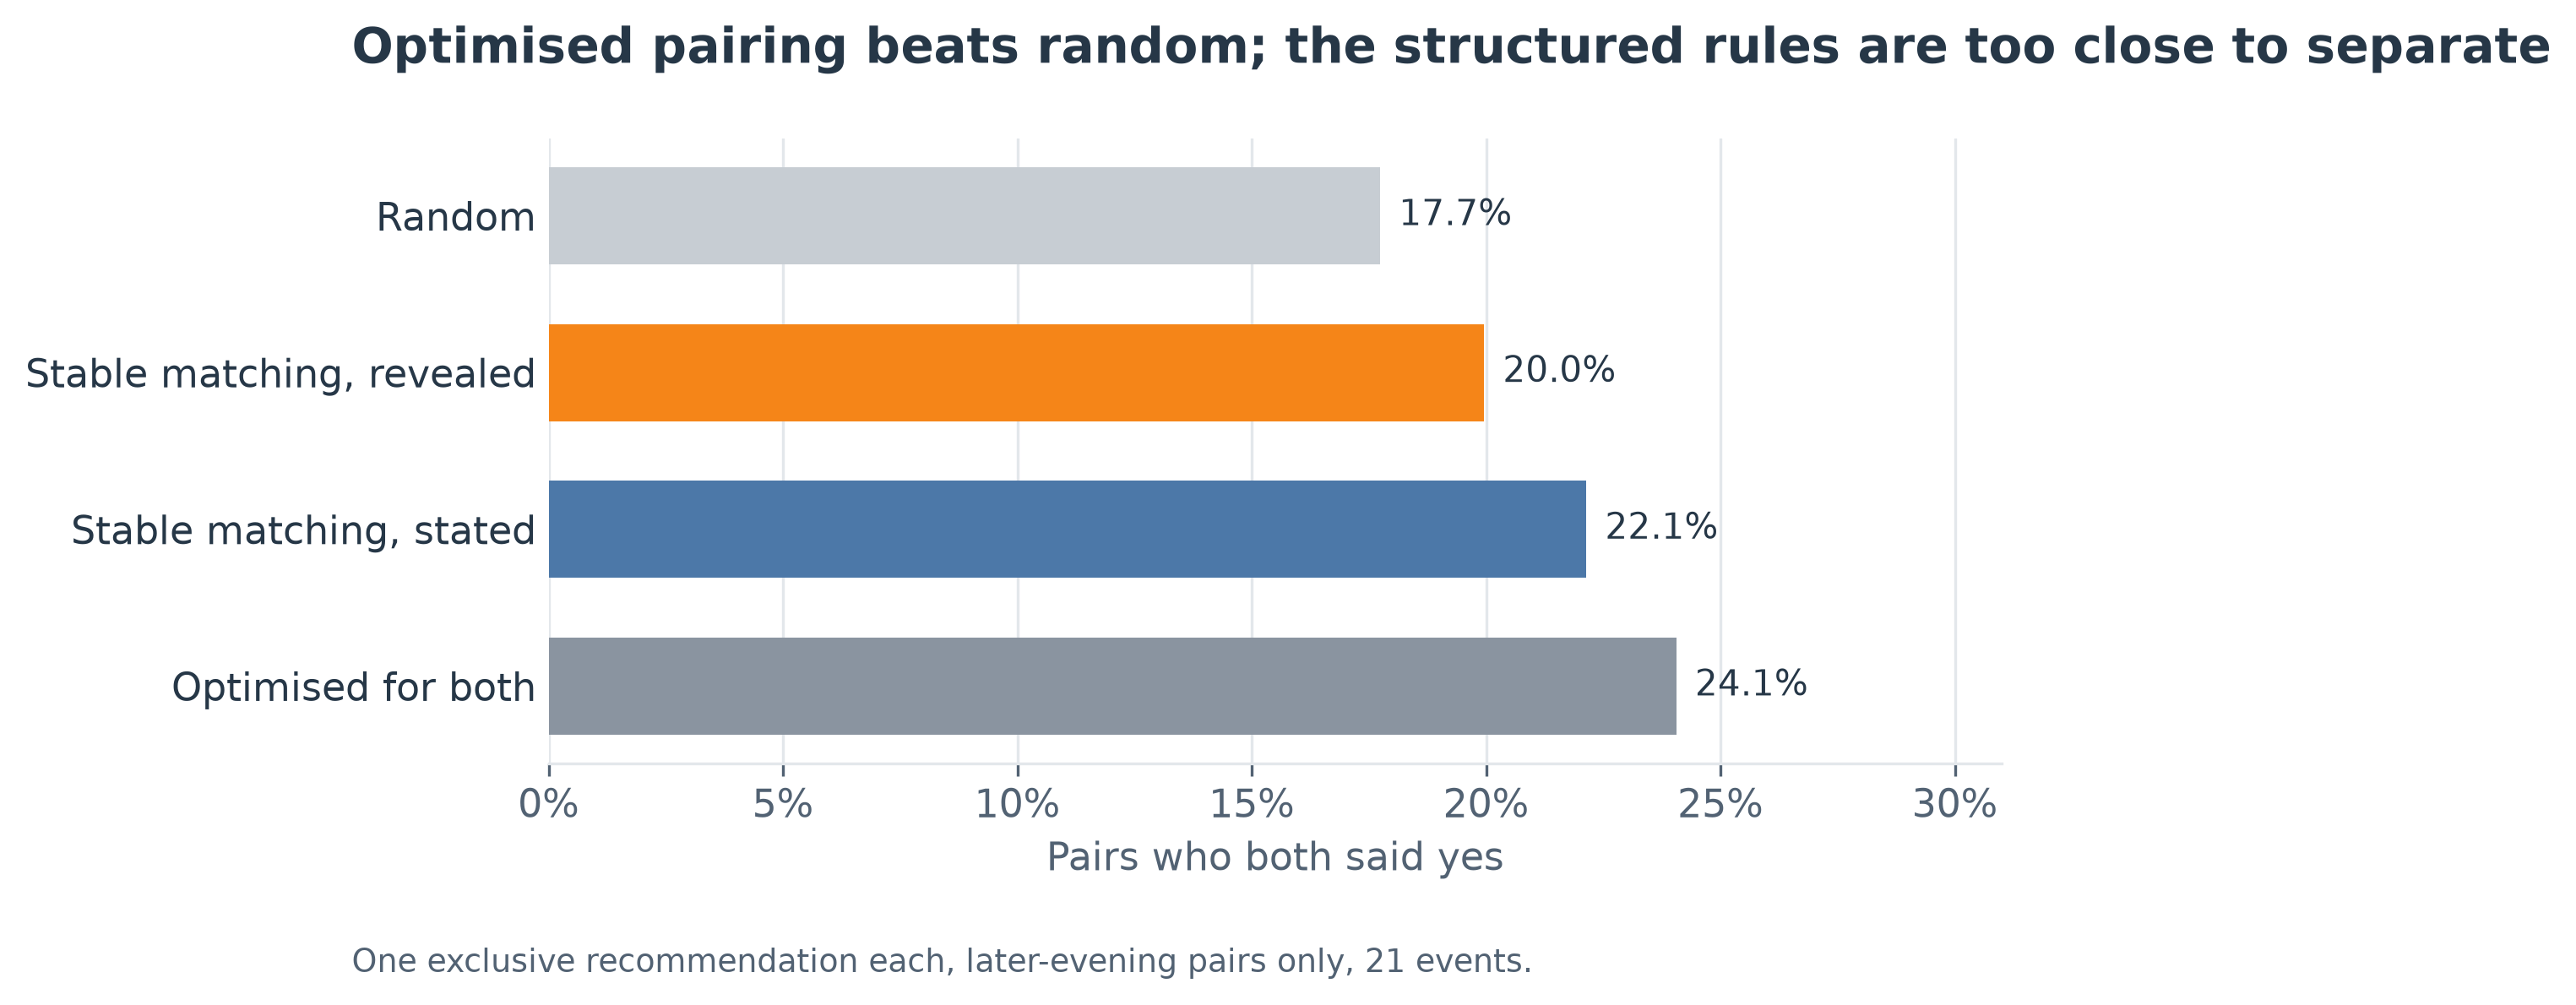

In [18]:
chart("ext_s3_market.png")

In [19]:
for name in ["s3_market", "s3_lifts"]:
    print(name)
    display(show(name))

s3_market


,slots,random,stated,revealed,optimised
0,1,0.177,0.221,0.200,0.241
1,2,0.174,0.218,0.221,0.225


s3_lifts


,slots,comparison,lift_pp,events,ci_low,ci_high,p
0,1,optimised minus random,6.317,21,2.478,10.321,0.003
1,1,stated minus random,4.398,21,-0.613,8.848,0.095
2,1,revealed minus random,2.218,21,-1.131,5.908,0.185
3,1,optimised minus stated,1.919,21,-4.436,8.803,0.531
4,1,revealed minus stated,-2.181,21,-7.628,3.373,0.451
5,2,optimised minus random,5.046,21,3.240,6.797,0.001
6,2,stated minus random,4.381,21,2.018,7.268,0.001
7,2,revealed minus random,4.641,21,2.163,7.016,0.001
8,2,optimised minus stated,0.665,21,-2.320,3.296,0.627
9,2,revealed minus stated,0.260,21,-3.129,3.645,0.859


## Robustness (R1 to R6)

Does the headline survive other ways of measuring it? R1 uses other people's ratings, R2 removes clipping, R3 reweights for dropouts, R4 drops the 1-10 survey waves, R5 and R6 test for segments.

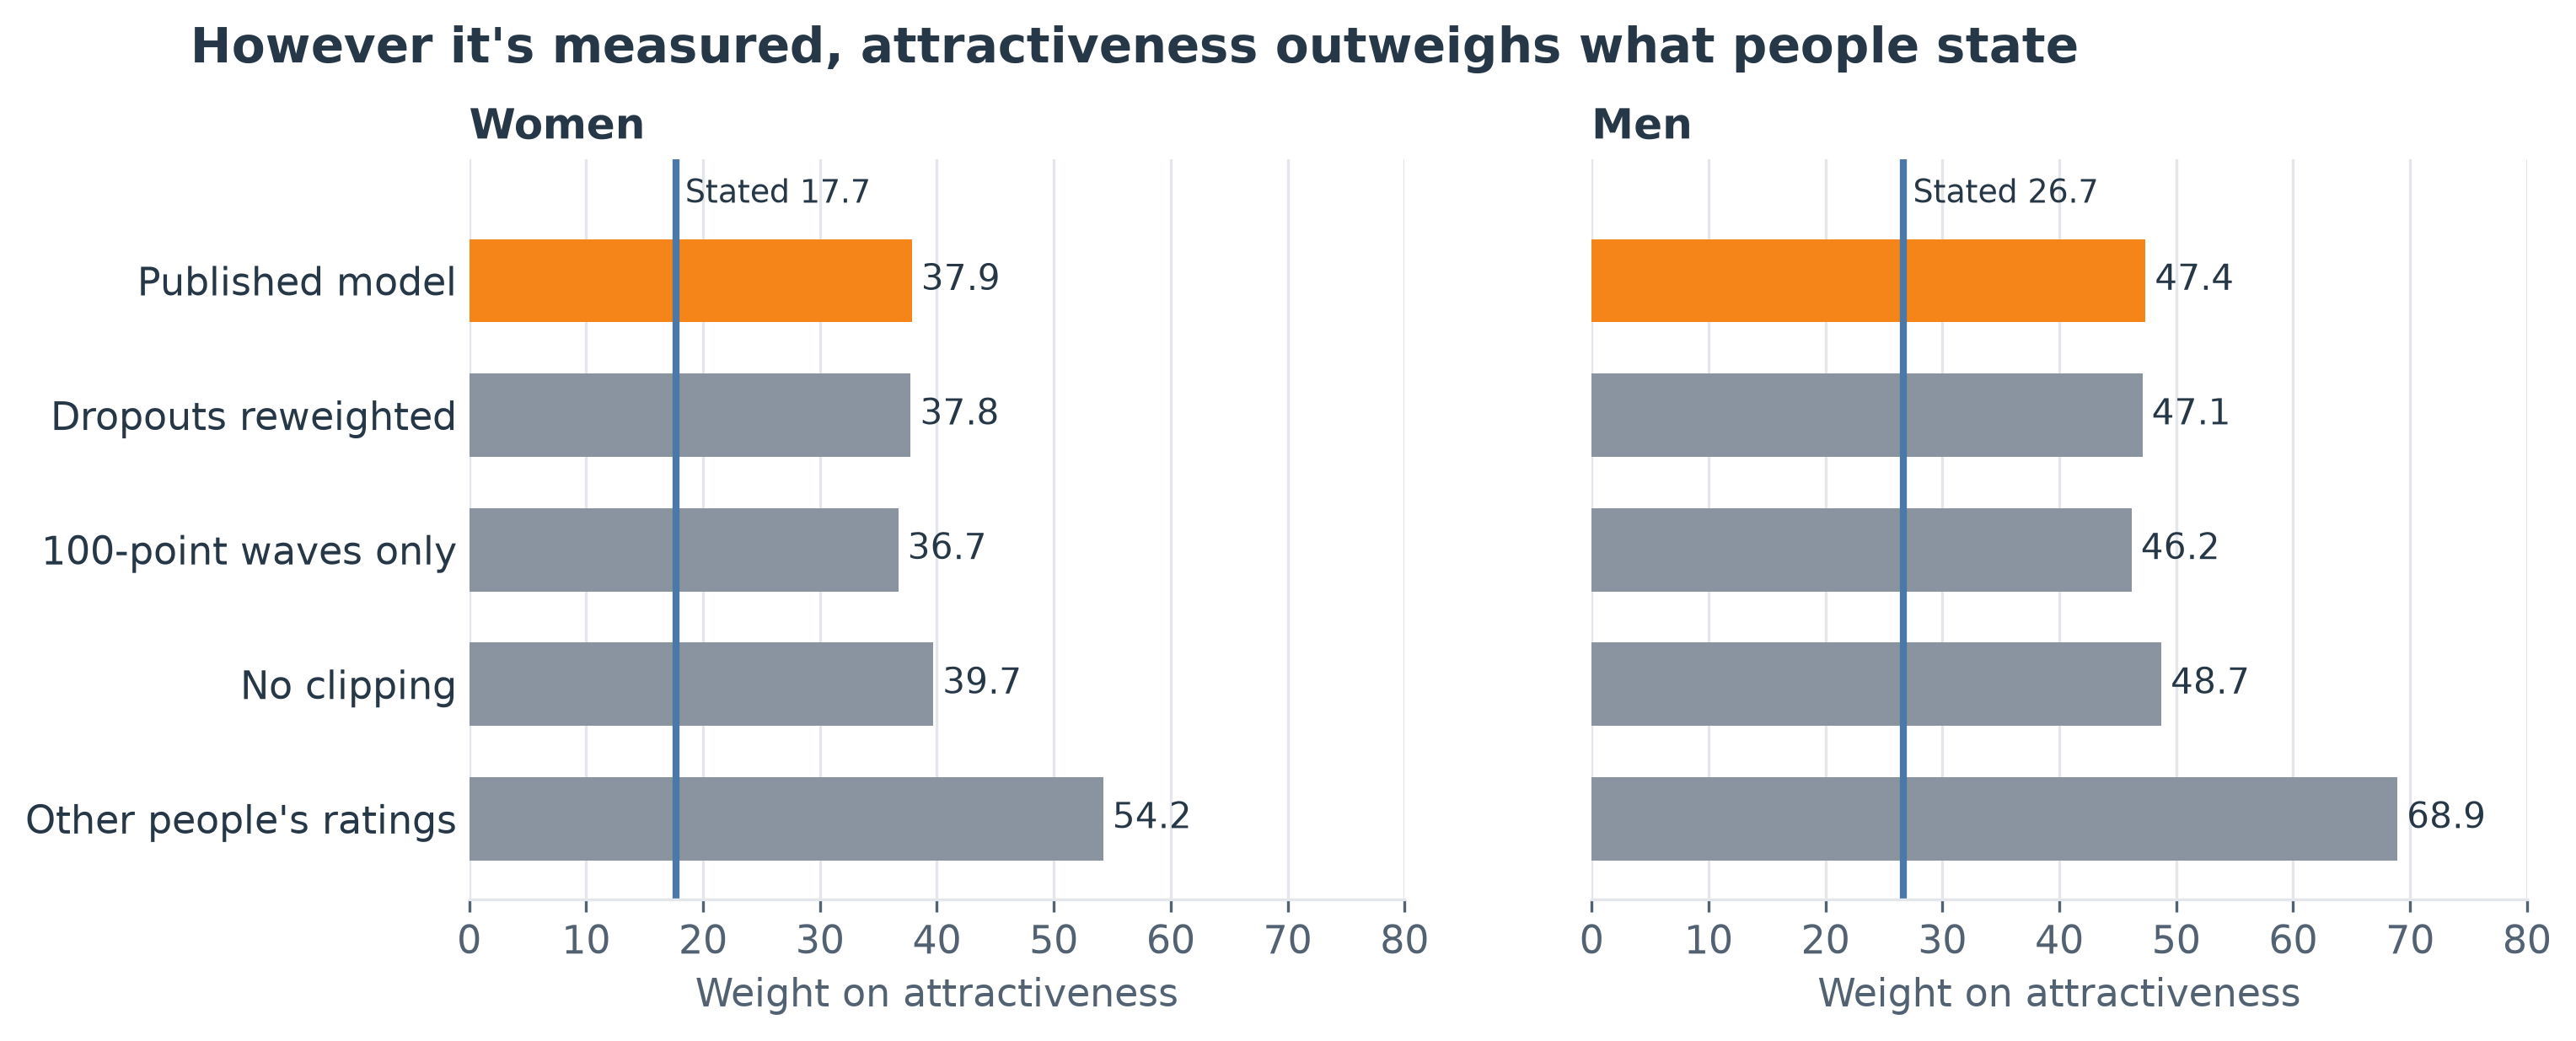

In [20]:
chart("ext_robustness.png")

In [21]:
for name in ["r1_consensus", "r2_relative_weights", "r3_dropout_weights", "r4_excluding_rating_waves", "r5_fit", "r5_classes", "r5_holdout", "r6_quality", "r6_outcomes", "r6_revealed_by_segment", "r6_choice_test"]:
    print(name)
    display(show(name))

r1_consensus


,gender,attribute,revealed_own_ratings,revealed_consensus,ci_low,ci_high,consensus_coefficient,agreement_own_vs_consensus,people
0,Women,Attractive,37.858,54.225,41.766,65.209,0.781,0.510,223
1,Women,Sincere,9.176,0.000,0.000,3.820,-0.089,0.271,223
2,Women,Intelligent,9.372,6.581,0.000,16.814,0.095,0.256,223
3,Women,Fun,19.804,16.828,2.688,28.245,0.242,0.417,223
4,Women,Ambitious,1.381,1.838,0.000,12.268,0.026,0.264,223
5,Women,Shared interests,22.409,20.528,7.274,32.479,0.296,0.289,223
6,Men,Attractive,47.367,68.916,56.794,77.521,1.000,0.518,229
7,Men,Sincere,2.186,0.000,0.000,0.000,-0.129,0.146,229
8,Men,Intelligent,6.028,13.367,4.026,20.907,0.194,0.198,229
9,Men,Fun,24.034,13.698,3.828,21.886,0.199,0.333,229


r2_relative_weights


,gender,attribute,relative_weight,ci_low,ci_high,clipped_importance,r_squared
0,Women,Attractive,39.690,34.638,43.964,37.858,0.360
1,Women,Sincere,4.135,2.596,6.214,9.176,0.360
2,Women,Intelligent,6.426,4.542,8.768,9.372,0.360
3,Women,Fun,22.087,18.931,25.347,19.804,0.360
4,Women,Ambitious,3.615,2.406,5.212,1.381,0.360
5,Women,Shared interests,24.047,20.347,27.757,22.409,0.360
6,Men,Attractive,48.724,43.164,54.161,47.367,0.386
7,Men,Sincere,3.461,2.063,5.491,2.186,0.386
8,Men,Intelligent,3.739,2.374,5.405,6.028,0.386
9,Men,Fun,23.453,20.337,26.603,24.034,0.386


r3_dropout_weights


,gender,attribute,unweighted,reweighted,change,largest_weight
0,Women,Attractive,37.864,37.766,-0.098,1.626
1,Women,Sincere,9.278,9.480,0.202,1.626
2,Women,Intelligent,9.313,9.573,0.260,1.626
3,Women,Fun,19.767,19.716,-0.051,1.626
4,Women,Ambitious,1.385,1.091,-0.294,1.626
5,Women,Shared interests,22.393,22.374,-0.019,1.626
6,Men,Attractive,47.309,47.106,-0.203,1.348
7,Men,Sincere,2.132,2.254,0.122,1.348
8,Men,Intelligent,6.123,6.010,-0.112,1.348
9,Men,Fun,24.058,24.194,0.136,1.348


... (12 outputs left out)

r6_revealed_by_segment


,gender,segment,people,stated_attractive,Attractive,Sincere,Intelligent,Fun,Ambitious,Shared interests
0,Women,0,136,15.121,36.772,10.194,10.384,19.569,0.442,22.640
1,Women,1,79,18.448,37.094,6.497,8.711,20.685,5.997,21.016
2,Women,2,8,53.500,56.596,11.255,0.000,10.790,0.000,21.358
3,Men,0,89,19.557,44.109,1.531,7.651,27.409,0.000,19.301
4,Men,1,105,24.446,45.666,5.129,7.301,19.941,0.000,21.963
5,Men,2,35,51.571,55.262,0.000,0.000,30.644,0.000,14.094


r6_choice_test


,gender,lr_statistic,df,p
0,Women,11.809,12,0.461
1,Men,17.233,12,0.141


## Tested, not recommended (N1 to N9)

Kept for the record. N9 is a sensitive topic and needs careful framing if used.

In [22]:
for name in ["n1_goal_weights", "n1_goal_tests", "n2_interest_similarity", "n3_size_weights", "n3_size_tests", "n4_polarising", "n5_instrumental_variables", "n6_first_choices", "n8_self_insight", "n9_stated_race_importance"]:
    print(name)
    display(show(name))

n1_goal_weights


,gender,goal,people,yes_rate,match_rate,Attractive,Sincere,Intelligent,Fun,Ambitious,Shared interests
0,Women,Casual,178,0.399,0.185,36.315,7.725,11.324,21.475,1.422,21.738
1,Women,Other,27,0.374,0.191,39.164,22.774,0.000,15.451,3.201,19.411
2,Women,Serious,18,0.392,0.146,51.308,14.230,0.000,3.205,1.839,29.417
3,Men,Casual,170,0.488,0.174,43.857,2.814,5.077,25.617,1.092,21.543
4,Men,Other,27,0.425,0.157,57.704,0.000,3.211,19.084,0.000,20.002
5,Men,Serious,32,0.477,0.190,54.373,0.296,9.302,20.913,0.000,15.116


n1_goal_tests


,gender,lr_statistic,df,p
0,Women,15.200,12,0.231
1,Men,24.056,12,0.020


n2_interest_similarity


,outcome,model,similarity_pp_per_sd,similarity_p,interaction_pp,interaction_p,people
0,dec,No ratings,1.877,0.006,0.411,0.541,452
1,dec,With ratings,0.351,0.522,0.392,0.467,452
2,match,No ratings,1.130,0.036,0.240,0.649,452
3,match,With ratings,0.353,0.481,0.259,0.614,452


... (10 outputs left out)

n8_self_insight


,people,survey_auc,population_auc,survey_better,tied,traits_r2,match_link,match_link_p
0,452,0.877,0.905,0.201,0.316,0.019,0.011,0.723


n9_stated_race_importance


,gender,people,mean_stated,same_race_pp,same_race_p,per_stated_point_pp,per_stated_point_p
0,Women,222,4.063,7.676,0.000,1.141,0.031
1,Men,229,3.402,0.504,0.718,1.004,0.037
